Montamos de drive

In [1]:
from google.colab import drive
from pathlib import Path
import os

# Montar Google Drive
drive.mount('/content/drive')



Mounted at /content/drive


In [2]:
# ============================================================
# ðŸšš Copiar OCT_base_cv5 de Drive -> disco local de Colab
#    âœ” con barra de progreso
#    âœ” copia train_outer / test_outer / indices
#    âœ” evita volver a copiar si ya existe
# ============================================================
from pathlib import Path
import shutil
from tqdm.auto import tqdm


DRIVE_ROOT = Path("/content/drive/MyDrive/TesisIA")
BASE_DATA_DIR_DRIVE = DRIVE_ROOT / "OCT_base_cv5"

# -------------------------------
# Destino local en Colab
# -------------------------------
LOCAL_ROOT = Path("/content")
BASE_DATA_DIR_LOCAL = LOCAL_ROOT / "OCT_base_cv5"

assert BASE_DATA_DIR_DRIVE.exists(), f"No existe el origen: {BASE_DATA_DIR_DRIVE}"

print("Origen :", BASE_DATA_DIR_DRIVE)
print("Destino:", BASE_DATA_DIR_LOCAL)

# ------------------------------------------------------------
# Utilidad: contar archivos
# ------------------------------------------------------------
def count_files(root: Path):
    return sum(1 for p in root.rglob("*") if p.is_file())

# ------------------------------------------------------------
# Copia con barra de progreso
# ------------------------------------------------------------
def copy_tree_with_progress(src: Path, dst: Path, overwrite=False):
    files = [p for p in src.rglob("*") if p.is_file()]
    print(f"\nArchivos a copiar: {len(files):,}")

    for src_file in tqdm(files, desc="Copiando OCT_base_cv5", unit="file"):
        rel = src_file.relative_to(src)
        dst_file = dst / rel
        dst_file.parent.mkdir(parents=True, exist_ok=True)

        if dst_file.exists() and not overwrite:
            continue

        shutil.copy2(src_file, dst_file)

# ------------------------------------------------------------
# Ejecutar copia sÃ³lo si no existe ya local
# ------------------------------------------------------------
if BASE_DATA_DIR_LOCAL.exists():
    print("\nâš ï¸ Ya existe una copia local de OCT_base_cv5.")
    print("Se reutilizarÃ¡ la copia local actual.")
else:
    print("\nIniciando copia al disco local de Colab...")
    copy_tree_with_progress(BASE_DATA_DIR_DRIVE, BASE_DATA_DIR_LOCAL, overwrite=False)
    print("\nâœ… Copia completada.")

# ------------------------------------------------------------
# VerificaciÃ³n rÃ¡pida
# ------------------------------------------------------------
num_drive = count_files(BASE_DATA_DIR_DRIVE)
num_local = count_files(BASE_DATA_DIR_LOCAL)

print("\nResumen:")
print(f" - Archivos en Drive : {num_drive:,}")
print(f" - Archivos en Local : {num_local:,}")

assert num_local > 0, "La copia local quedÃ³ vacÃ­a"
print("\nâœ… Base local lista para usarse.")

Origen : /content/drive/MyDrive/TesisIA/OCT_base_cv5
Destino: /content/OCT_base_cv5

Iniciando copia al disco local de Colab...

Archivos a copiar: 65


Copiando OCT_base_cv5:   0%|          | 0/65 [00:00<?, ?file/s]


âœ… Copia completada.

Resumen:
 - Archivos en Drive : 65
 - Archivos en Local : 65

âœ… Base local lista para usarse.


Cargamos los folds

In [3]:
# ============================================================
# ðŸ“ ConfiguraciÃ³n del dataset base Ãºnico + TODOS los Ã­ndices por fold
#    (usando copia LOCAL en /content)
# ============================================================
from pathlib import Path
import json
import pandas as pd
import numpy as np


# âš ï¸ A partir de aquÃ­ TODO se lee desde disco local
BASE_DATA_DIR = LOCAL_ROOT / "OCT_base_cv5"
INDICES_DIR   = BASE_DATA_DIR / "indices"

TRAIN_BASE_DIR = BASE_DATA_DIR / "train_outer"
TEST_BASE_DIR  = BASE_DATA_DIR / "test_outer"

TRAIN_BASE_INDEX_CSV = TRAIN_BASE_DIR / "train_outer_base_index.csv"
TEST_BASE_INDEX_CSV  = TEST_BASE_DIR  / "test_outer_base_index.csv"

TRAIN_BASE_META_JSON = TRAIN_BASE_DIR / "train_outer_meta.json"
TEST_BASE_META_JSON  = TEST_BASE_DIR  / "test_outer_meta.json"

FOLD_IDS = [1, 2, 3, 4, 5]

# -------------------------------
# Mapeo REAL heredado del notebook 1DivisionDataset
# -------------------------------
IDX_TO_CLASS = {
    0: "CNV",
    1: "DRUSEN",
    2: "NORMAL"
}
CLASS_TO_IDX = {v: k for k, v in IDX_TO_CLASS.items()}
CLASS_NAMES = [IDX_TO_CLASS[i] for i in sorted(IDX_TO_CLASS)]

print("Mapeo de clases activo:")
print(IDX_TO_CLASS)

# -------------------------------
# VerificaciÃ³n de rutas y archivos base
# -------------------------------
assert BASE_DATA_DIR.exists(), f"No existe BASE_DATA_DIR local: {BASE_DATA_DIR}"
assert INDICES_DIR.exists(), f"No existe INDICES_DIR: {INDICES_DIR}"

required_files = [
    TRAIN_BASE_INDEX_CSV,
    TEST_BASE_INDEX_CSV,
    TRAIN_BASE_META_JSON,
    TEST_BASE_META_JSON,
]

missing = [str(p) for p in required_files if not p.exists()]
assert not missing, f"Faltan archivos requeridos:\n" + "\n".join(missing)

# -------------------------------
# Cargar Ã­ndices base
# -------------------------------
df_train_base = pd.read_csv(TRAIN_BASE_INDEX_CSV)
df_test_base  = pd.read_csv(TEST_BASE_INDEX_CSV)

print(f"\nTrain base: {len(df_train_base):,} muestras")
print(f"Test  base: {len(df_test_base):,} muestras")

# -------------------------------
# Cargar metadata de shards
# -------------------------------
with open(TRAIN_BASE_META_JSON, "r", encoding="utf-8") as f:
    train_meta = json.load(f)

with open(TEST_BASE_META_JSON, "r", encoding="utf-8") as f:
    test_meta = json.load(f)

print("\nResumen de shards:")
print(f" - Train shards: {train_meta.get('num_shards', 'N/D')}")
print(f" - Test  shards: {test_meta.get('num_shards', 'N/D')}")

# -------------------------------
# Resolver archivos de Ã­ndices del fold (.npy)
# -------------------------------
def find_fold_index_file(indices_dir: Path, fold: int, split_name: str) -> Path:
    candidates = [
        indices_dir / f"fold_{fold}_{split_name}_idx.npy",
        indices_dir / f"fold{fold}_{split_name}_idx.npy",
        indices_dir / f"{split_name}_fold_{fold}_idx.npy",
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(
        f"No encontrÃ© archivo de Ã­ndices .npy para fold={fold}, split='{split_name}' en {indices_dir}"
    )

# -------------------------------
# Cargar TODOS los folds
# -------------------------------
fold_train_idx_map = {}
fold_val_idx_map = {}

for fold_id in FOLD_IDS:
    train_idx_path = find_fold_index_file(INDICES_DIR, fold_id, "train")
    val_idx_path   = find_fold_index_file(INDICES_DIR, fold_id, "val")

    train_idx = np.load(train_idx_path)
    val_idx   = np.load(val_idx_path)

    assert isinstance(train_idx, np.ndarray), f"Fold {fold_id}: train_idx debe ser np.ndarray"
    assert isinstance(val_idx, np.ndarray),   f"Fold {fold_id}: val_idx debe ser np.ndarray"

    assert train_idx.ndim == 1, f"Fold {fold_id}: train_idx debe ser vector 1D"
    assert val_idx.ndim == 1,   f"Fold {fold_id}: val_idx debe ser vector 1D"

    assert np.issubdtype(train_idx.dtype, np.integer), f"Fold {fold_id}: train_idx debe contener enteros"
    assert np.issubdtype(val_idx.dtype, np.integer),   f"Fold {fold_id}: val_idx debe contener enteros"

    assert ((train_idx >= 0) & (train_idx < len(df_train_base))).all(), \
        f"Fold {fold_id}: hay base_idx fuera de rango en train"

    assert ((val_idx >= 0) & (val_idx < len(df_train_base))).all(), \
        f"Fold {fold_id}: hay base_idx fuera de rango en val"

    train_idx_set = set(train_idx.tolist())
    val_idx_set   = set(val_idx.tolist())

    assert len(train_idx_set & val_idx_set) == 0, \
        f"Fold {fold_id}: hay solapamiento entre train y val"

    fold_train_idx_map[fold_id] = train_idx
    fold_val_idx_map[fold_id] = val_idx

    print(f"\nFold {fold_id}")
    print(f" - Train idx: {train_idx_path.name} -> {len(train_idx):,}")
    print(f" - Val   idx: {val_idx_path.name} -> {len(val_idx):,}")

assert df_train_base.index.is_unique, "El Ã­ndice de df_train_base debe ser Ãºnico"

print("\nâœ… ConfiguraciÃ³n del dataset base y todos los Ã­ndices de folds cargada correctamente.")

Mapeo de clases activo:
{0: 'CNV', 1: 'DRUSEN', 2: 'NORMAL'}

Train base: 10,128 muestras
Test  base: 2,521 muestras

Resumen de shards:
 - Train shards: 20
 - Test  shards: 5

Fold 1
 - Train idx: fold_1_train_idx.npy -> 8,190
 - Val   idx: fold_1_val_idx.npy -> 1,938

Fold 2
 - Train idx: fold_2_train_idx.npy -> 8,214
 - Val   idx: fold_2_val_idx.npy -> 1,914

Fold 3
 - Train idx: fold_3_train_idx.npy -> 7,876
 - Val   idx: fold_3_val_idx.npy -> 2,252

Fold 4
 - Train idx: fold_4_train_idx.npy -> 8,195
 - Val   idx: fold_4_val_idx.npy -> 1,933

Fold 5
 - Train idx: fold_5_train_idx.npy -> 8,037
 - Val   idx: fold_5_val_idx.npy -> 2,091

âœ… ConfiguraciÃ³n del dataset base y todos los Ã­ndices de folds cargada correctamente.


Dataset desde shards base + Ã­ndices del fold

In [4]:
# ============================================================
# Dataset desde shards base + base_idx
# ============================================================
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset


class OCTShardsIndexedDataset(Dataset):
    """
    Dataset que lee muestras ya preprocesadas desde shards .npy
    usando Ã­ndices globales (base_idx) sobre el dataset base materializado.

    Espera en base_index_df columnas como:
      - shard_id
      - shard_pos
      - label_id
    """

    def __init__(
        self,
        base_dir,
        base_index_df,
        base_indices,
        transform=None,
        shard_id_col="shard_id",
        shard_pos_col="shard_pos",
        label_col="label_id",
    ):
        super().__init__()

        self.base_dir = Path(base_dir)
        self.base_index_df = base_index_df.reset_index(drop=True).copy()
        self.base_indices = np.asarray(base_indices, dtype=np.int64)
        self.transform = transform

        self.shard_id_col = shard_id_col
        self.shard_pos_col = shard_pos_col
        self.label_col = label_col

        required_cols = [self.shard_id_col, self.shard_pos_col, self.label_col]
        missing = [c for c in required_cols if c not in self.base_index_df.columns]
        if missing:
            raise KeyError(f"Faltan columnas requeridas en base_index_df: {missing}")

        if self.base_indices.ndim != 1:
            raise ValueError("base_indices debe ser un vector 1D")

        if len(self.base_indices) == 0:
            raise ValueError("base_indices estÃ¡ vacÃ­o")

        if (self.base_indices < 0).any() or (self.base_indices >= len(self.base_index_df)).any():
            raise IndexError("Hay base_indices fuera de rango respecto a base_index_df")

        self.x_shard_map = self._build_shard_map(kind="X")
        self.y_shard_map = self._build_shard_map(kind="y")

        if set(self.x_shard_map.keys()) != set(self.y_shard_map.keys()):
            raise ValueError(
                "Los shard_id detectados para X e y no coinciden.\n"
                f"X: {sorted(self.x_shard_map.keys())}\n"
                f"y: {sorted(self.y_shard_map.keys())}"
            )

        # cache simple
        self._x_cache = {}
        self._y_cache = {}

    def __len__(self):
        return len(self.base_indices)

    def _extract_shard_id(self, path: Path):
        """
        Extrae el shard_id desde el nombre del archivo.
        Ejemplos esperados:
          train_outer_X_000.npy
          test_outer_y_004.npy
        """
        m = re.search(r"_(\d+)\.npy$", path.name)
        if m is None:
            raise ValueError(f"No pude extraer shard_id del archivo: {path.name}")
        return int(m.group(1))

    def _build_shard_map(self, kind="X"):
        assert kind in ("X", "y")
        pattern = f"*_{kind}_*.npy"
        files = sorted(self.base_dir.glob(pattern))

        if not files:
            raise FileNotFoundError(
                f"No encontrÃ© archivos con patrÃ³n '{pattern}' en {self.base_dir}"
            )

        shard_map = {}
        for fp in files:
            sid = self._extract_shard_id(fp)
            shard_map[sid] = fp

        return shard_map

    def _load_npy_cached(self, path, cache_dict):
        path = str(path)
        if path not in cache_dict:
            cache_dict[path] = np.load(path, mmap_mode="r")
        return cache_dict[path]

    def __getitem__(self, idx):
        base_idx = int(self.base_indices[idx])
        row = self.base_index_df.iloc[base_idx]

        shard_id = int(row[self.shard_id_col])
        shard_pos = int(row[self.shard_pos_col])

        if shard_id not in self.x_shard_map:
            raise KeyError(f"shard_id={shard_id} no existe en x_shard_map")
        if shard_id not in self.y_shard_map:
            raise KeyError(f"shard_id={shard_id} no existe en y_shard_map")

        x_path = self.x_shard_map[shard_id]
        y_path = self.y_shard_map[shard_id]

        X_shard = self._load_npy_cached(x_path, self._x_cache)
        y_shard = self._load_npy_cached(y_path, self._y_cache)

        x = np.array(X_shard[shard_pos], copy=True)
        y = int(y_shard[shard_pos])

        x = torch.from_numpy(x).float()
        y = torch.tensor(y, dtype=torch.long)

        if self.transform is not None:
            x = self.transform(x)

        return x, y

Vamos a crear las instancias de los datasets

In [5]:
# ============================================================
# ðŸ“¦ TEST DATASET
# ============================================================

test_ds = OCTShardsIndexedDataset(
    base_dir=TEST_BASE_DIR,
    base_index_df=df_test_base,
    base_indices=np.arange(len(df_test_base)),
    transform=None
)

print(f"Test externo = {len(test_ds):,}")

Test externo = 2,521


In [6]:
# ============================================================
# ðŸ”Ž Sanity check de lectura desde shards
#    (usando fold 1 sÃ³lo para verificaciÃ³n)
# ============================================================
SANITY_FOLD = 1

train_ds_sanity = OCTShardsIndexedDataset(
    base_dir=TRAIN_BASE_DIR,
    base_index_df=df_train_base,
    base_indices=fold_train_idx_map[SANITY_FOLD],
    transform=None
)

val_ds_sanity = OCTShardsIndexedDataset(
    base_dir=TRAIN_BASE_DIR,
    base_index_df=df_train_base,
    base_indices=fold_val_idx_map[SANITY_FOLD],
    transform=None
)

x0, y0 = train_ds_sanity[0]
x1, y1 = val_ds_sanity[0]
x2, y2 = test_ds[0]

print(f"TRAIN (fold {SANITY_FOLD})")
print(" - shape :", tuple(x0.shape))
print(" - dtype :", x0.dtype)
print(" - min/max:", float(x0.min()), float(x0.max()))
print(" - label_id:", int(y0))
print(" - class   :", IDX_TO_CLASS[int(y0)])

print(f"\nVAL (fold {SANITY_FOLD})")
print(" - shape :", tuple(x1.shape))
print(" - dtype :", x1.dtype)
print(" - min/max:", float(x1.min()), float(x1.max()))
print(" - label_id:", int(y1))
print(" - class   :", IDX_TO_CLASS[int(y1)])

print("\nTEST")
print(" - shape :", tuple(x2.shape))
print(" - dtype :", x2.dtype)
print(" - min/max:", float(x2.min()), float(x2.max()))
print(" - label_id:", int(y2))
print(" - class   :", IDX_TO_CLASS[int(y2)])

assert x0.ndim == 3 and x0.shape[0] == 1, "Train sample no tiene shape [1, H, W]"
assert x1.ndim == 3 and x1.shape[0] == 1, "Val sample no tiene shape [1, H, W]"
assert x2.ndim == 3 and x2.shape[0] == 1, "Test sample no tiene shape [1, H, W]"

assert x0.shape[-2:] == (512, 512), "Train sample no tiene tamaÃ±o 512x512"
assert x1.shape[-2:] == (512, 512), "Val sample no tiene tamaÃ±o 512x512"
assert x2.shape[-2:] == (512, 512), "Test sample no tiene tamaÃ±o 512x512"

print("\nâœ… Lectura desde shards OK.")

TRAIN (fold 1)
 - shape : (1, 512, 512)
 - dtype : torch.float32
 - min/max: -1.012591004371643 3.018557548522949
 - label_id: 0
 - class   : CNV

VAL (fold 1)
 - shape : (1, 512, 512)
 - dtype : torch.float32
 - min/max: -0.9874330759048462 3.915626287460327
 - label_id: 0
 - class   : CNV

TEST
 - shape : (1, 512, 512)
 - dtype : torch.float32
 - min/max: -0.9794790744781494 3.687673807144165
 - label_id: 0
 - class   : CNV

âœ… Lectura desde shards OK.


DataLoader de Test

In [7]:
# ============================================================
# ðŸšš DATALOADER DE TEST
# ============================================================
import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 8
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
PIN_MEMORY = torch.cuda.is_available()

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

print("Test DataLoader creado correctamente:\n")
print(f"Test batches: {len(test_loader):,}")
print(f"\nBATCH_SIZE  = {BATCH_SIZE}")
print(f"NUM_WORKERS = {NUM_WORKERS}")
print(f"PIN_MEMORY  = {PIN_MEMORY}")

Test DataLoader creado correctamente:

Test batches: 316

BATCH_SIZE  = 8
NUM_WORKERS = 2
PIN_MEMORY  = True


In [8]:
# ============================================================
# ðŸ”Ž Sanity check de batch
#    (usando fold 1 sÃ³lo para verificaciÃ³n)
# ============================================================
SANITY_FOLD = 1

train_ds_sanity = OCTShardsIndexedDataset(
    base_dir=TRAIN_BASE_DIR,
    base_index_df=df_train_base,
    base_indices=fold_train_idx_map[SANITY_FOLD],
    transform=None
)

train_loader_sanity = DataLoader(
    train_ds_sanity,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

xb, yb = next(iter(train_loader_sanity))

print(f"Batch sanity (fold {SANITY_FOLD})")
print("Batch X shape :", tuple(xb.shape))
print("Batch X dtype :", xb.dtype)
print("Batch y shape :", tuple(yb.shape))
print("Batch y dtype :", yb.dtype)

print("Min/Max batch :", float(xb.min()), float(xb.max()))
print("Labels batch  :", yb[:10].tolist())

assert xb.ndim == 4 and xb.shape[1:] == (1, 512, 512), "Batch X no tiene shape [B,1,512,512]"
assert yb.ndim == 1, "Batch y no tiene shape [B]"

print("\nâœ… Batch OK.")

Batch sanity (fold 1)
Batch X shape : (8, 1, 512, 512)
Batch X dtype : torch.float32
Batch y shape : (8,)
Batch y dtype : torch.int64
Min/Max batch : -1.3707674741744995 5.4220452308654785
Labels batch  : [1, 2, 1, 0, 2, 1, 0, 0]

âœ… Batch OK.


Comenzamos con el modelo hibrido CSWin Transformer + FPN

La estrcutura es la siguiente:


1.   CSWin Transformer como Encoder â†’ Extrae caracterÃ­sticas profundas y globales.
2.   FPN
3.   Cabeza de ClasificaciÃ³n

Copiamos el repositorio de GitHub (Oficial)

In [9]:
# Carpeta de CSWin Transformer
CSWIN_DIR = "/content/drive/MyDrive/TesisIA/CSWin-Transformer"
#!rm -rf "$CSWIN_DIR"
#!git clone https://github.com/microsoft/CSWin-Transformer.git "$CSWIN_DIR"

# Inspeccionamos
import os, textwrap, pathlib
print("Repo clonado en:", CSWIN_DIR)
print("\nArchivos top-level:", os.listdir(CSWIN_DIR)[:15])


Repo clonado en: /content/drive/MyDrive/TesisIA/CSWin-Transformer

Archivos top-level: ['.git', 'CODE_OF_CONDUCT.md', 'LICENSE', 'README.md', 'SECURITY.md', 'SUPPORT.md', 'checkpoint_saver.py', 'dataset', 'finetune.py', 'finetune.sh', 'install_req.sh', 'labeled_memcached_dataset.py', 'main.py', 'models', 'segmentation']


In [10]:
# Dependencias mÃ­nimas y modernas
!pip -q install --upgrade timm einops opencv-python scikit-image scikit-learn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 147.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 162.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 161.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cucim-cu12 26.2.0 requires scikit-image<0.26.0,>=0.19.0, but you have scikit-image 0.26.0 which is incompatible.


In [11]:
import sys, importlib, inspect, os

assert os.path.isdir(CSWIN_DIR), CSWIN_DIR
sys.path.insert(0, CSWIN_DIR)

#Importamos CSWin
m = importlib.import_module("models.cswin")
print("== CLASES en models.cswin ==")
print([n for n,_ in inspect.getmembers(m, inspect.isclass)])
print("\n== FUNCIONES en models.cswin ==")
print([n for n,_ in inspect.getmembers(m, inspect.isfunction)])

== CLASES en models.cswin ==
['CSWinBlock', 'CSWinTransformer', 'DropPath', 'LePEAttention', 'Merge_Block', 'Mlp', 'Rearrange', 'partial']

== FUNCIONES en models.cswin ==
['CSWin_144_24322_large_224', 'CSWin_144_24322_large_384', 'CSWin_64_12211_tiny_224', 'CSWin_64_24322_small_224', 'CSWin_96_24322_base_224', 'CSWin_96_24322_base_384', '_cfg', '_conv_filter', 'img2windows', 'load_pretrained', 'register_model', 'to_2tuple', 'trunc_normal_', 'windows2img']


/usr/local/lib/python3.12/dist-packages/timm/models/helpers.py:7: FutureWarning: Importing from timm.models.helpers is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


Creamos el Backbone CSWin Transformer, asÃ­ como la FPN y la Head de clasificaciÃ³n

In [12]:
# ============================================================
# CODEx update 2026-04-07: CSWin backbone + FPN + multi-scale head
# ============================================================
import os
import math
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import OrderedDict


def _bchw_to_tokens(x_bchw):
    # [B,C,H,W] -> [B,N,C]
    B, C, H, W = x_bchw.shape
    x = x_bchw.permute(0, 2, 3, 1).reshape(B, H * W, C).contiguous()
    return x, H, W


def _tokens_to_bchw(x_tokens, H, W):
    # [B,N,C] -> [B,C,H,W]
    B, N, C = x_tokens.shape
    assert H * W == N, f"Esperaba N=H*W; N={N}, H*W={H*W}"
    x = x_tokens.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()
    return x


IMG_SIZE_MODEL = IMG_SIZE if 'IMG_SIZE' in globals() else 512
class CSWinBackbone(nn.Module):
    def __init__(self, ckpt_path=None, freeze_backbone=False):
        super().__init__()
        self.model = timm.create_model(
            "cswin_tiny",
            pretrained=False,
            num_classes=0,
            img_size=IMG_SIZE_MODEL
        )
        if ckpt_path and os.path.exists(ckpt_path):
            state = torch.load(ckpt_path, map_location="cpu")
            state_dict = state["state_dict"] if isinstance(state, dict) and "state_dict" in state else state
            missing, unexpected = self.model.load_state_dict(state_dict, strict=False)
            print("[CSWin] missing keys:", len(missing), "| unexpected:", len(unexpected))
        else:
            print("[CSWin] ckpt no encontrado, usando pesos inicializados por timm.")

        if freeze_backbone:
            for p in self.model.parameters():
                p.requires_grad = False

        self.out_channels = [64, 128, 256, 512]

    def _tokens_hw(self, x_tokens):
        B, N, C = x_tokens.shape
        H = W = int(math.sqrt(N))
        assert H * W == N, f"Tokens no cuadrados: N={N}"
        return _tokens_to_bchw(x_tokens, H, W)

    def forward(self, x):
        m = self.model
        x = m.patch_embed(x)
        if getattr(m, "pos_embed", None) is not None:
            x = x + m.pos_embed
        x = m.pos_drop(x)

        feats = []

        x = m.stage1(x)
        feats.append(self._tokens_hw(x))
        if hasattr(m, "merge1") and m.merge1 is not None:
            x = m.merge1(x)

        x = m.stage2(x)
        feats.append(self._tokens_hw(x))
        if hasattr(m, "merge2") and m.merge2 is not None:
            x = m.merge2(x)

        x = m.stage3(x)
        feats.append(self._tokens_hw(x))
        if hasattr(m, "merge3") and m.merge3 is not None:
            x = m.merge3(x)

        x = m.stage4(x)
        feats.append(self._tokens_hw(x))
        return feats


class ConvBNAct(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, s=1, p=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=k, stride=s, padding=p, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU()
        )

    def forward(self, x):
        return self.block(x)


class FPN(nn.Module):
    def __init__(self, in_channels_list, out_channels=256):
        super().__init__()
        self.lateral = nn.ModuleList([
            nn.Conv2d(in_ch, out_channels, kernel_size=1) for in_ch in in_channels_list
        ])
        self.smooth = nn.ModuleList([
            ConvBNAct(out_channels, out_channels, k=3, s=1, p=1) for _ in in_channels_list
        ])

    def _up_add(self, x, y):
        return F.interpolate(x, size=y.shape[-2:], mode="nearest") + y

    def forward(self, feats):
        C1, C2, C3, C4 = feats
        L1, L2, L3, L4 = [lat(c) for lat, c in zip(self.lateral, [C1, C2, C3, C4])]
        P4 = L4
        P3 = self._up_add(P4, L3)
        P2 = self._up_add(P3, L2)
        P1 = self._up_add(P2, L1)

        pyr = OrderedDict(
            P1=self.smooth[0](P1),
            P2=self.smooth[1](P2),
            P3=self.smooth[2](P3),
            P4=self.smooth[3](P4),
        )
        return pyr


class FPNClassifierHead(nn.Module):
    def __init__(self, in_channels=256, num_classes=3, dropout=0.25):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.norm = nn.LayerNorm(in_channels * 4)
        self.classifier = nn.Sequential(
            nn.Linear(in_channels * 4, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, pyramid):
        pooled = []
        for level_name in ("P1", "P2", "P3", "P4"):
            pooled.append(self.pool(pyramid[level_name]).flatten(1))
        x = torch.cat(pooled, dim=1)
        x = self.norm(x)
        return self.classifier(x)


class CSWinFPNClassifier(nn.Module):
    def __init__(self, num_classes=3, ckpt_path=None, freeze_backbone=False):
        super().__init__()
        self.backbone = CSWinBackbone(ckpt_path=ckpt_path, freeze_backbone=freeze_backbone)
        self.fpn = FPN(self.backbone.out_channels, out_channels=256)
        self.head = FPNClassifierHead(in_channels=256, num_classes=num_classes, dropout=0.25)

    def forward(self, x):
        feats = self.backbone(x)
        pyr = self.fpn(feats)
        logits = self.head(pyr)
        return logits


# La instancia del modelo se crea despues, cuando el entorno y los checkpoints ya estan cargados.

Constructor reutilizable del CSWin base y del modelo final

In [13]:
# ============================================================
# ðŸ—ï¸ Constructor reutilizable del modelo
# ============================================================
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_cswin_base(num_classes=3):
    CSWinTransformer = m.CSWinTransformer

    cswin_base = CSWinTransformer(
        img_size=512,
        patch_size=4,
        in_chans=1,
        num_classes=num_classes,
        embed_dim=64,
        depth=[1, 2, 21, 1],
        split_size=[1, 2, 8, 8],
        num_heads=[2, 4, 8, 16],
        mlp_ratio=4.0,
        drop_rate=0.0,
        attn_drop_rate=0.0,
        drop_path_rate=0.2,
    )

    ckpt_path = "/content/drive/MyDrive/TesisIA/CSWin-Transformer/cswin_tiny_224.pth"
    raw = torch.load(ckpt_path, map_location="cpu")

    state = None
    for k in ("state_dict_ema", "state_dict", "model"):
        if isinstance(raw, dict) and k in raw and isinstance(raw[k], dict):
            state = raw[k]
            break
    if state is None:
        state = raw if isinstance(raw, dict) else {}

    state = {(k[7:] if k.startswith("module.") else k): v for k, v in state.items()}

    # quitar primera conv y head
    for k in ["stage1_conv_embed.0.weight", "stage1_conv_embed.0.bias", "head.weight", "head.bias"]:
        state.pop(k, None)

    model_sd = cswin_base.state_dict()
    filtered = {
        k: v for k, v in state.items()
        if k in model_sd and isinstance(v, torch.Tensor) and v.shape == model_sd[k].shape
    }

    cswin_base.load_state_dict(filtered, strict=False)

    # Adaptar 1Âª conv RGB -> gris
    target_conv = cswin_base.stage1_conv_embed[0]
    t_out = target_conv.out_channels
    kH, kW = target_conv.kernel_size

    src_state = raw.get("state_dict_ema", raw.get("state_dict", raw if isinstance(raw, dict) else {}))
    cands = [(k, w) for k, w in src_state.items() if isinstance(w, torch.Tensor) and w.ndim == 4 and w.shape[1] == 3]
    cands.sort(key=lambda kv: (kv[1].shape[2] != kH or kv[1].shape[3] != kW, kv[1].shape[0] != t_out))

    if not cands:
        raise ValueError("No encontrÃ© conv con in=3 en el checkpoint.")

    conv_key, w_rgb = cands[0]

    with torch.no_grad():
        w_gray = w_rgb.mean(dim=1, keepdim=True)
        if w_gray.shape[0] != t_out:
            mcopy = min(w_gray.shape[0], t_out)
            target_conv.weight.zero_()
            target_conv.weight[:mcopy, :, :kH, :kW].copy_(w_gray[:mcopy])
        else:
            target_conv.weight.copy_(w_gray)

        b_key = conv_key.replace(".weight", ".bias")
        b_rgb = src_state.get(b_key, None)
        if b_rgb is not None and target_conv.bias is not None:
            if b_rgb.shape[0] == t_out:
                target_conv.bias.copy_(b_rgb)
            else:
                mcopy = min(b_rgb.shape[0], t_out)
                target_conv.bias.zero_()
                target_conv.bias[:mcopy].copy_(b_rgb[:mcopy])

    return cswin_base


def build_fpn_model(num_classes=3):
    cswin_base = build_cswin_base(num_classes=num_classes).to(device)
    net = CSWinFPNClassifier(cswin_base, num_classes=num_classes).to(device)
    return net

Funciones axuliares de entrenamiento.

In [14]:
# ============================================================
# CODEx update 2026-04-07: Funciones auxiliares de entrenamiento con timing
# ============================================================
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch import optim
from tqdm.auto import tqdm
import matplotlib.pyplot as plt


def _get_logits(output):
    return output[0] if isinstance(output, (tuple, list)) else output


def run_epoch_pb(net, loader, optimizer, criterion, scaler, device,
                 train=True, grad_clip=1.0, desc="train"):
    net.train(mode=train)
    total, correct, loss_sum = 0, 0, 0.0
    start_time = time.perf_counter()

    pbar = tqdm(loader, desc=desc, leave=False)
    for batch in pbar:
        x = batch["image"].to(device, non_blocking=True)
        y = batch["label"].to(device, non_blocking=True)

        if train:
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                logits = _get_logits(net(x))
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            if grad_clip is not None and grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(net.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            with torch.no_grad():
                with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                    logits = _get_logits(net(x))
                    loss = criterion(logits, y)

        bs = y.size(0)
        loss_sum += loss.item() * bs
        pred = logits.argmax(dim=1)
        correct += (pred == y).sum().item()
        total += bs

        pbar.set_postfix({
            "loss": f"{loss_sum / max(total, 1):.4f}",
            "acc": f"{correct / max(total, 1):.4f}"
        })

    wall_time = time.perf_counter() - start_time
    timing = {
        "wall_time_sec": float(wall_time),
        "num_batches": int(len(loader)),
        "num_samples": int(total),
        "sec_per_batch": float(wall_time / max(1, len(loader))),
        "ms_per_image": float((wall_time / max(1, total)) * 1000.0),
        "samples_per_sec": float(total / max(wall_time, 1e-12)),
    }
    return loss_sum / max(total, 1), correct / max(total, 1), timing


def plot_history(history, fold_id=None):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(epochs, history["train_loss"], marker="o", label="Train loss")
    ax[0].plot(epochs, history["val_loss"], marker="o", label="Val loss")
    ax[0].set_title(f"PÃ©rdida Fold {fold_id}" if fold_id is not None else "PÃ©rdida")
    ax[0].set_xlabel("Ã‰poca")
    ax[0].legend()
    ax[0].grid(True, alpha=0.3)

    ax[1].plot(epochs, history["train_acc"], marker="o", label="Train acc")
    ax[1].plot(epochs, history["val_acc"], marker="o", label="Val acc")
    ax[1].plot(epochs, history["val_f1_macro"], marker="o", label="Val F1 macro")
    ax[1].set_title(f"MÃ©tricas Fold {fold_id}" if fold_id is not None else "MÃ©tricas")
    ax[1].set_xlabel("Ã‰poca")
    ax[1].legend()
    ax[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


In [15]:
# ============================================================
# ðŸŽ¨ Augment ligero para train (sobre shards ya preprocesados)
# ============================================================
import math
import random
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF

class OCTTrainAugment:
    """
    Augment ligero para OCT ya preprocesado y z-scoreado.
    Espera tensor [1, H, W].
    """

    def __init__(
        self,
        p_rotate=0.5,
        max_deg=5.0,
        p_shift=0.5,
        max_shift_frac=0.03,
        p_brightness=0.5,
        brightness_delta=0.10,
        p_contrast=0.5,
        contrast_delta=0.10,
    ):
        self.p_rotate = p_rotate
        self.max_deg = max_deg

        self.p_shift = p_shift
        self.max_shift_frac = max_shift_frac

        self.p_brightness = p_brightness
        self.brightness_delta = brightness_delta

        self.p_contrast = p_contrast
        self.contrast_delta = contrast_delta

    def __call__(self, x):
        """
        x: tensor [1, H, W], float32 (z-score)
        """
        if not torch.is_tensor(x):
            raise TypeError("OCTTrainAugment espera un torch.Tensor")

        if x.ndim != 3 or x.shape[0] != 1:
            raise ValueError(f"Se esperaba tensor [1,H,W], recibido {tuple(x.shape)}")

        _, H, W = x.shape

        # ----------------------------------------------------
        # 1) RotaciÃ³n pequeÃ±a
        # ----------------------------------------------------
        if random.random() < self.p_rotate:
            angle = random.uniform(-self.max_deg, self.max_deg)
            x = TF.rotate(
                x,
                angle=angle,
                interpolation=TF.InterpolationMode.BILINEAR,
                fill=0.0
            )

        # ----------------------------------------------------
        # 2) Shift horizontal pequeÃ±o
        # ----------------------------------------------------
        if random.random() < self.p_shift:
            max_dx = int(round(W * self.max_shift_frac))
            dx = random.randint(-max_dx, max_dx)

            theta = torch.tensor([
                [1.0, 0.0, 2.0 * dx / max(W - 1, 1)],
                [0.0, 1.0, 0.0]
            ], dtype=x.dtype, device=x.device).unsqueeze(0)

            grid = F.affine_grid(theta, size=(1, 1, H, W), align_corners=False)
            x = F.grid_sample(
                x.unsqueeze(0),
                grid,
                mode="bilinear",
                padding_mode="reflection",
                align_corners=False
            ).squeeze(0)

        # ----------------------------------------------------
        # 3) Brightness
        # ----------------------------------------------------
        if random.random() < self.p_brightness:
            delta = random.uniform(-self.brightness_delta, self.brightness_delta)
            x = x + delta

        # ----------------------------------------------------
        # 4) Contrast
        # ----------------------------------------------------
        if random.random() < self.p_contrast:
            factor = random.uniform(1.0 - self.contrast_delta, 1.0 + self.contrast_delta)
            mean = x.mean()
            x = (x - mean) * factor + mean

        return x.float()


# Instancia global
train_transform = OCTTrainAugment(
    p_rotate=0.5,
    max_deg=5.0,
    p_shift=0.5,
    max_shift_frac=0.03,
    p_brightness=0.5,
    brightness_delta=0.10,
    p_contrast=0.5,
    contrast_delta=0.10,
)

print("Augment de train definido correctamente.")

Augment de train definido correctamente.


Entrenamiento 5-fold con checkpoints por fold


FOLD 1/5
Conteos por clase fold 1: [2123, 2464, 3603]
Pesos de clase fold 1: [1.2240999937057495, 1.0547000169754028, 0.7213000059127808]
[Fold 1] Epoch 1: freeze parcial | params backbone entrenables=21349763


Fold 1 | Train:   0%|          | 0/1024 [00:00<?, ?it/s]

[Fold 1] Epoch 01/6 | train_loss=0.4822 train_acc=0.8392 | val_loss=0.3729 val_acc=0.9045 val_f1=0.8860 | train_t=190.41s val_t=14.12s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold1.pt
[Fold 1] Epoch 2: backbone completo | params backbone entrenables=21802819


Fold 1 | Train:   0%|          | 0/1024 [00:00<?, ?it/s]

[Fold 1] Epoch 02/6 | train_loss=0.3292 train_acc=0.9247 | val_loss=0.5011 val_acc=0.8927 val_f1=0.8707 | train_t=210.84s val_t=14.08s


...

[Fold 1] Epoch 04/6 | train_loss=0.2190 train_acc=0.9597 | val_loss=0.4880 val_acc=0.8947 val_f1=0.8725 | train_t=211.08s val_t=14.08s


Fold 1 | Train:   0%|          | 0/1024 [00:00<?, ?it/s]

[Fold 1] Epoch 05/6 | train_loss=0.1959 train_acc=0.9695 | val_loss=0.5197 val_acc=0.8973 val_f1=0.8734 | train_t=200.78s val_t=13.98s


Fold 1 | Train:   0%|          | 0/1024 [00:00<?, ?it/s]

[Fold 1] Epoch 06/6 | train_loss=0.1921 train_acc=0.9694 | val_loss=0.5404 val_acc=0.8849 val_f1=0.8691 | train_t=189.52s val_t=14.01s
[Fold 1] Resumen tiempos | train_total=1192.14s | val_total=84.23s | fold_total=1277.05s


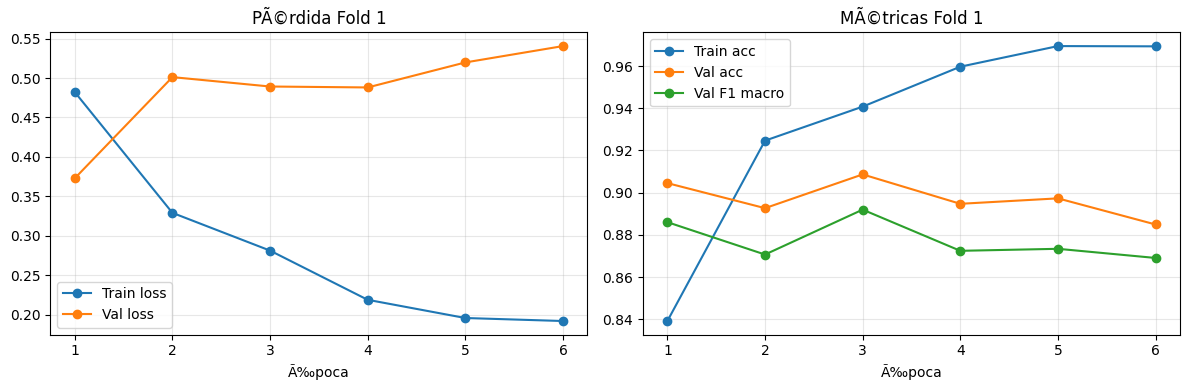


FOLD 2/5
Conteos por clase fold 2: [2052, 2467, 3695]
Pesos de clase fold 2: [1.256700038909912, 1.045300006866455, 0.6978999972343445]
[Fold 2] Epoch 1: freeze parcial | params backbone entrenables=21349763


Fold 2 | Train:   0%|          | 0/1027 [00:00<?, ?it/s]

[Fold 2] Epoch 01/6 | train_loss=0.5207 train_acc=0.8223 | val_loss=0.6168 val_acc=0.8412 val_f1=0.8347 | train_t=182.52s val_t=13.95s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold2.pt
[Fold 2] Epoch 2: backbone completo | params backbone entrenables=21802819


Fold 2 | Train:   0%|          | 0/1027 [00:00<?, ?it/s]

[Fold 2] Epoch 02/6 | train_loss=0.3401 train_acc=0.9216 | val_loss=0.3798 val_acc=0.9237 val_f1=0.9168 | train_t=201.05s val_t=13.84s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold2.pt


...

[Fold 2] Epoch 04/6 | train_loss=0.2400 train_acc=0.9562 | val_loss=0.5181 val_acc=0.8866 val_f1=0.8790 | train_t=212.03s val_t=13.88s


Fold 2 | Train:   0%|          | 0/1027 [00:00<?, ?it/s]

[Fold 2] Epoch 05/6 | train_loss=0.2250 train_acc=0.9623 | val_loss=0.3858 val_acc=0.9222 val_f1=0.9144 | train_t=202.50s val_t=13.85s


Fold 2 | Train:   0%|          | 0/1027 [00:00<?, ?it/s]

[Fold 2] Epoch 06/6 | train_loss=0.2073 train_acc=0.9665 | val_loss=0.4540 val_acc=0.9054 val_f1=0.8993 | train_t=190.57s val_t=13.82s
[Fold 2] Resumen tiempos | train_total=1181.46s | val_total=83.17s | fold_total=1265.32s


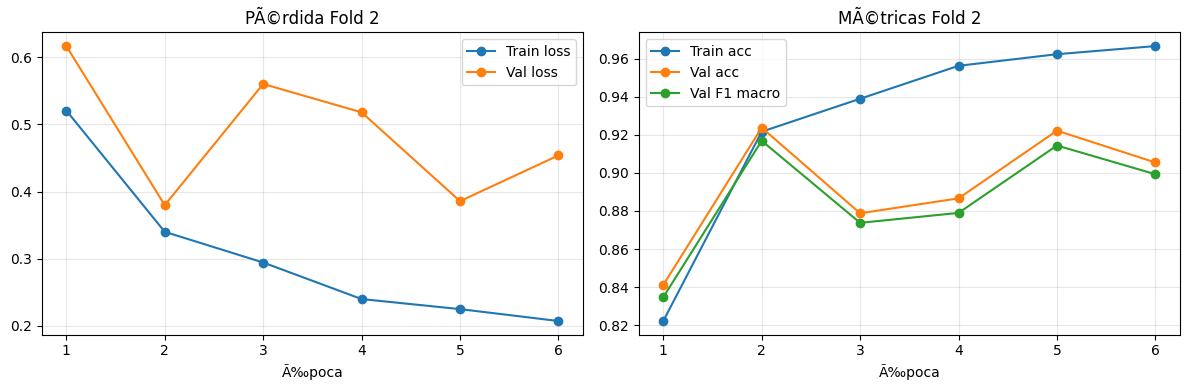


FOLD 3/5
Conteos por clase fold 3: [2130, 2166, 3580]
Pesos de clase fold 3: [1.1634999513626099, 1.1441999673843384, 0.692300021648407]
[Fold 3] Epoch 1: freeze parcial | params backbone entrenables=21349763


Fold 3 | Train:   0%|          | 0/985 [00:00<?, ?it/s]

[Fold 3] Epoch 01/6 | train_loss=0.5083 train_acc=0.8334 | val_loss=0.5588 val_acc=0.8388 val_f1=0.8456 | train_t=181.08s val_t=16.32s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold3.pt
[Fold 3] Epoch 2: backbone completo | params backbone entrenables=21802819


Fold 3 | Train:   0%|          | 0/985 [00:00<?, ?it/s]

[Fold 3] Epoch 02/6 | train_loss=0.3183 train_acc=0.9322 | val_loss=0.5463 val_acc=0.8770 val_f1=0.8831 | train_t=195.12s val_t=16.28s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold3.pt


...

[Fold 3] Epoch 04/6 | train_loss=0.2358 train_acc=0.9568 | val_loss=0.7815 val_acc=0.8552 val_f1=0.8659 | train_t=204.55s val_t=16.29s


Fold 3 | Train:   0%|          | 0/985 [00:00<?, ?it/s]

[Fold 3] Epoch 05/6 | train_loss=0.2131 train_acc=0.9657 | val_loss=0.6813 val_acc=0.8619 val_f1=0.8627 | train_t=184.77s val_t=16.41s


Fold 3 | Train:   0%|          | 0/985 [00:00<?, ?it/s]

[Fold 3] Epoch 06/6 | train_loss=0.2047 train_acc=0.9674 | val_loss=0.6168 val_acc=0.8845 val_f1=0.8880 | train_t=203.19s val_t=16.27s
[Fold 3] Resumen tiempos | train_total=1153.48s | val_total=97.85s | fold_total=1252.33s


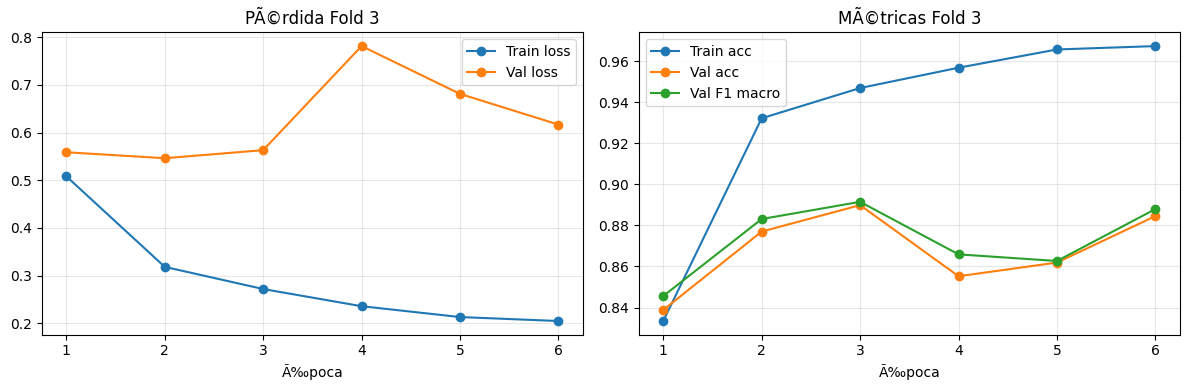


FOLD 4/5
Conteos por clase fold 4: [2200, 2219, 3776]
Pesos de clase fold 4: [1.1655000448226929, 1.155500054359436, 0.6790000200271606]
[Fold 4] Epoch 1: freeze parcial | params backbone entrenables=21349763


Fold 4 | Train:   0%|          | 0/1025 [00:00<?, ?it/s]

[Fold 4] Epoch 01/6 | train_loss=0.5008 train_acc=0.8333 | val_loss=0.3801 val_acc=0.9131 val_f1=0.9134 | train_t=187.45s val_t=14.05s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold4.pt
[Fold 4] Epoch 2: backbone completo | params backbone entrenables=21802819


Fold 4 | Train:   0%|          | 0/1025 [00:00<?, ?it/s]

[Fold 4] Epoch 02/6 | train_loss=0.3173 train_acc=0.9280 | val_loss=0.5426 val_acc=0.8919 val_f1=0.8963 | train_t=202.71s val_t=13.98s


...

[Fold 4] Epoch 04/6 | train_loss=0.2378 train_acc=0.9557 | val_loss=0.5207 val_acc=0.8939 val_f1=0.8965 | train_t=211.10s val_t=13.98s


Fold 4 | Train:   0%|          | 0/1025 [00:00<?, ?it/s]

[Fold 4] Epoch 05/6 | train_loss=0.2157 train_acc=0.9651 | val_loss=0.4326 val_acc=0.9079 val_f1=0.9131 | train_t=201.63s val_t=14.22s


Fold 4 | Train:   0%|          | 0/1025 [00:00<?, ?it/s]

[Fold 4] Epoch 06/6 | train_loss=0.2060 train_acc=0.9674 | val_loss=0.4801 val_acc=0.8929 val_f1=0.8986 | train_t=192.05s val_t=13.99s
[Fold 4] Resumen tiempos | train_total=1186.69s | val_total=84.37s | fold_total=1271.74s


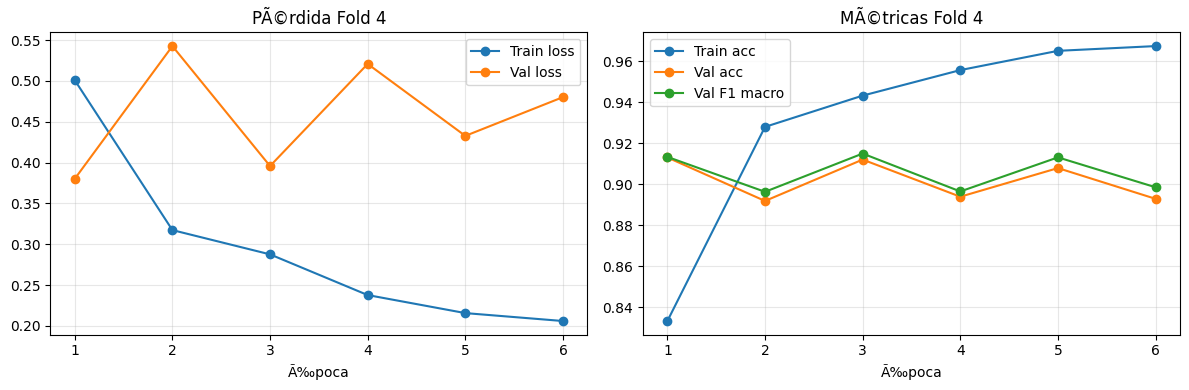


FOLD 5/5
Conteos por clase fold 5: [2055, 2296, 3686]
Pesos de clase fold 5: [1.2231999635696411, 1.0947999954223633, 0.6819999814033508]
[Fold 5] Epoch 1: freeze parcial | params backbone entrenables=21349763


Fold 5 | Train:   0%|          | 0/1005 [00:00<?, ?it/s]

[Fold 5] Epoch 01/6 | train_loss=0.5079 train_acc=0.8329 | val_loss=0.3771 val_acc=0.9101 val_f1=0.9086 | train_t=184.77s val_t=15.19s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold5.pt
[Fold 5] Epoch 2: backbone completo | params backbone entrenables=21802819


Fold 5 | Train:   0%|          | 0/1005 [00:00<?, ?it/s]

[Fold 5] Epoch 02/6 | train_loss=0.3267 train_acc=0.9280 | val_loss=0.3589 val_acc=0.9249 val_f1=0.9221 | train_t=200.34s val_t=15.14s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold5.pt


...

[Fold 5] Epoch 04/6 | train_loss=0.2373 train_acc=0.9579 | val_loss=0.3044 val_acc=0.9426 val_f1=0.9406 | train_t=209.43s val_t=15.17s
  -> Nuevo mejor checkpoint guardado: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold5.pt


Fold 5 | Train:   0%|          | 0/1005 [00:00<?, ?it/s]

[Fold 5] Epoch 05/6 | train_loss=0.2288 train_acc=0.9587 | val_loss=0.3796 val_acc=0.9287 val_f1=0.9250 | train_t=187.95s val_t=15.25s


Fold 5 | Train:   0%|          | 0/1005 [00:00<?, ?it/s]

[Fold 5] Epoch 06/6 | train_loss=0.2100 train_acc=0.9652 | val_loss=0.3208 val_acc=0.9378 val_f1=0.9355 | train_t=211.01s val_t=15.14s
[Fold 5] Resumen tiempos | train_total=1181.39s | val_total=91.10s | fold_total=1273.78s


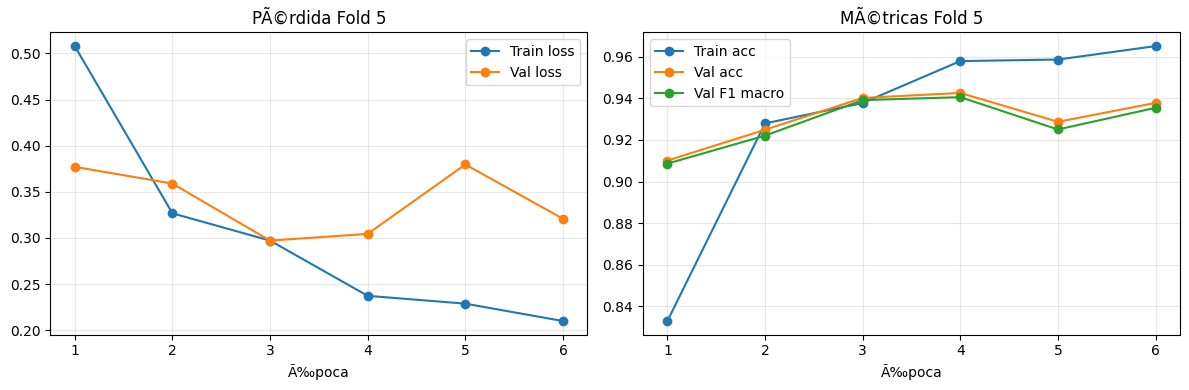

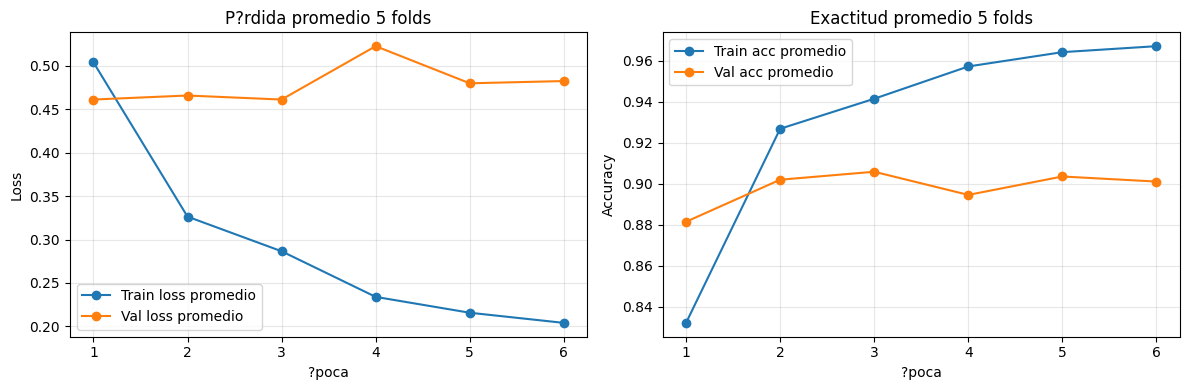

In [18]:
# ============================================================
# CODEx update 2026-04-07: Entrenamiento CSWin+FPN con freeze parcial, class weights y tiempos
# ============================================================
import os
import gc
import time
import math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

NUM_CLASSES = 3
EPOCHS = 6
MILESTONE_EVERY = 3

RESUME_FOLDS = True

FREEZE_BACKBONE_EPOCHS = 1
FREEZE_BACKBONE_PREFIXES = ("stage1", "stage2")
TRAIN_DEVICE = device if 'device' in globals() else (DEVICE if 'DEVICE' in globals() else torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
TRAIN_BATCH_SIZE = BATCH_SIZE if 'BATCH_SIZE' in globals() else 8
TRAIN_NUM_WORKERS = NUM_WORKERS if 'NUM_WORKERS' in globals() else (2 if torch.cuda.is_available() else 0)
TRAIN_PIN_MEMORY = PIN_MEMORY if 'PIN_MEMORY' in globals() else torch.cuda.is_available()
TRAIN_N_FOLDS = N_FOLDS if 'N_FOLDS' in globals() else 5
TRAIN_SAVE_DIR = str((DRIVE_ROOT / 'checkpoints_cswin_fpn_A100') if 'DRIVE_ROOT' in globals() else (Path('/content/drive/MyDrive/TesisIA') / 'checkpoints_cswin_fpn_A100'))
os.makedirs(TRAIN_SAVE_DIR, exist_ok=True)


def get_fold_split_indices(fold_id):
    if 'fold_train_idx_map' in globals() and 'fold_val_idx_map' in globals():
        if fold_id in fold_train_idx_map and fold_id in fold_val_idx_map:
            return fold_train_idx_map[fold_id], fold_val_idx_map[fold_id]

    if 'fold_indices' in globals() and fold_id in fold_indices:
        return fold_indices[fold_id]['train'], fold_indices[fold_id]['val']

    if 'INDICES_DIR' in globals():
        indices_dir = INDICES_DIR
    else:
        from pathlib import Path
        indices_dir = Path('./OCT_base_cv5/indices')

    from pathlib import Path
    indices_dir = Path(indices_dir)
    train_path = indices_dir / f'fold_{fold_id}_train_idx.npy'
    val_path = indices_dir / f'fold_{fold_id}_val_idx.npy'
    if not train_path.exists() or not val_path.exists():
        raise FileNotFoundError(f'No encontre indices para fold={fold_id} en {indices_dir}')
    return np.load(train_path), np.load(val_path)

def compute_class_weights_from_indices(base_index_df, base_indices, num_classes):
    labels = base_index_df.iloc[base_indices]["label_id"].to_numpy()
    counts = np.bincount(labels, minlength=num_classes).astype(np.float32)
    counts = np.maximum(counts, 1.0)
    weights = counts.sum() / (num_classes * counts)
    weights = weights / weights.mean()
    return torch.tensor(weights, dtype=torch.float32, device=TRAIN_DEVICE), counts.astype(int)


def set_backbone_trainable(model, trainable, prefixes=FREEZE_BACKBONE_PREFIXES):
    backbone_module = model.backbone.model if hasattr(model.backbone, "model") else model.backbone
    for name, param in backbone_module.named_parameters():
        if name.startswith(prefixes):
            param.requires_grad = trainable

def get_trainable_param_count(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


@torch.no_grad()
def evaluate_with_metrics(net, loader, device, criterion):
    net.eval()
    y_true, y_pred = [], []
    loss_sum, total, correct = 0.0, 0, 0
    start_time = time.perf_counter()
    for batch in loader:
        if isinstance(batch, dict):
            x = batch["image"].to(device)
            y = batch["label"].to(device)
        else:
            x, y = batch
            x = x.to(device)
            y = y.to(device)
        logits = net(x)
        loss = criterion(logits, y)

        pred = logits.argmax(1)
        loss_sum += loss.item() * y.size(0)
        total += y.size(0)
        correct += (pred == y).sum().item()
        y_true.extend(y.cpu().numpy().tolist())
        y_pred.extend(pred.cpu().numpy().tolist())

    wall_time = time.perf_counter() - start_time
    metrics = {
        "loss": loss_sum / max(total, 1),
        "acc": correct / max(total, 1),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "timing": {
            "wall_time_sec": float(wall_time),
            "num_batches": int(len(loader)),
            "num_samples": int(total),
            "sec_per_batch": float(wall_time / max(1, len(loader))),
            "ms_per_image": float((wall_time / max(1, total)) * 1000.0),
            "samples_per_sec": float(total / max(wall_time, 1e-12)),
        }
    }
    return metrics


def build_repo_fpn_classifier(num_classes, target_device, freeze_backbone=False):
    if "build_cswin_base" not in globals():
        raise RuntimeError("build_cswin_base no esta definido; reejecuta la celda del constructor reutilizable del modelo.")
    if "FPN" not in globals() or "FPNClassifierHead" not in globals():
        raise RuntimeError("FPN o FPNClassifierHead no estan definidos; reejecuta la celda del backbone/FPN.")

    def _local_run_stage(stage_module, x):
        if isinstance(stage_module, nn.ModuleList):
            for block in stage_module:
                x = block(x)
            return x
        return stage_module(x)

    class RepoCSWinFPNClassifier(nn.Module):
        def __init__(self, num_classes=3, freeze_backbone=False):
            super().__init__()
            self.backbone = build_cswin_base(num_classes=num_classes)
            if freeze_backbone:
                for p in self.backbone.parameters():
                    p.requires_grad = False
            self.fpn = FPN([64, 128, 256, 512], out_channels=256)
            self.head = FPNClassifierHead(in_channels=256, num_classes=num_classes, dropout=0.25)

        def _tokens_to_bchw(self, x_tokens):
            B, N, C = x_tokens.shape
            H = W = int(math.sqrt(N))
            if H * W != N:
                raise ValueError(f"Tokens no cuadrados: N={N}")
            return x_tokens.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()

        def forward(self, x):
            m = self.backbone
            x = m.stage1_conv_embed(x)
            feats = []

            x = _local_run_stage(m.stage1, x)
            feats.append(self._tokens_to_bchw(x))
            if hasattr(m, "merge1") and m.merge1 is not None:
                x = m.merge1(x)

            x = _local_run_stage(m.stage2, x)
            feats.append(self._tokens_to_bchw(x))
            if hasattr(m, "merge2") and m.merge2 is not None:
                x = m.merge2(x)

            x = _local_run_stage(m.stage3, x)
            feats.append(self._tokens_to_bchw(x))
            if hasattr(m, "merge3") and m.merge3 is not None:
                x = m.merge3(x)

            x = _local_run_stage(m.stage4, x)
            feats.append(self._tokens_to_bchw(x))

            pyr = self.fpn(feats)
            return self.head(pyr)

    return RepoCSWinFPNClassifier(num_classes=num_classes, freeze_backbone=freeze_backbone).to(target_device)


def train_build_model(num_classes):
    return build_repo_fpn_classifier(num_classes=num_classes, target_device=TRAIN_DEVICE, freeze_backbone=False)


def train_run_epoch(net, loader, optimizer, criterion, scaler, device,
                    train=True, grad_clip=1.0, desc="train"):
    net.train(mode=train)
    total, correct, loss_sum = 0, 0, 0.0
    start_time = time.perf_counter()

    pbar = tqdm(loader, desc=desc, leave=False)
    for batch in pbar:
        if isinstance(batch, dict):
            x = batch["image"].to(device, non_blocking=True)
            y = batch["label"].to(device, non_blocking=True)
        else:
            x, y = batch
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

        if train:
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                logits = net(x)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            if grad_clip is not None and grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(net.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            with torch.no_grad():
                with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                    logits = net(x)
                    loss = criterion(logits, y)

        bs = y.size(0)
        loss_sum += loss.item() * bs
        pred = logits.argmax(dim=1)
        correct += (pred == y).sum().item()
        total += bs

        pbar.set_postfix({
            "loss": f"{loss_sum / max(total, 1):.4f}",
            "acc": f"{correct / max(total, 1):.4f}"
        })

    wall_time = time.perf_counter() - start_time
    timing = {
        "wall_time_sec": float(wall_time),
        "num_batches": int(len(loader)),
        "num_samples": int(total),
        "sec_per_batch": float(wall_time / max(1, len(loader))),
        "ms_per_image": float((wall_time / max(1, total)) * 1000.0),
        "samples_per_sec": float(total / max(wall_time, 1e-12)),
    }
    return loss_sum / max(total, 1), correct / max(total, 1), timing


histories = {}
best_ckpts = {}

for fold_id in range(1, TRAIN_N_FOLDS + 1):
    print("\n" + "=" * 80)
    print(f"FOLD {fold_id}/{TRAIN_N_FOLDS}")
    print("=" * 80)

    train_idx, val_idx = get_fold_split_indices(fold_id)


    train_ds = OCTShardsIndexedDataset(
        base_dir=TRAIN_BASE_DIR,
        base_index_df=df_train_base,
        base_indices=train_idx,
        transform=train_transform
    )
    val_ds = OCTShardsIndexedDataset(
        base_dir=TRAIN_BASE_DIR,
        base_index_df=df_train_base,
        base_indices=val_idx,
        transform=None
    )

    train_loader = DataLoader(
        train_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=True,
        num_workers=TRAIN_NUM_WORKERS, pin_memory=TRAIN_PIN_MEMORY
    )
    val_loader = DataLoader(
        val_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=False,
        num_workers=TRAIN_NUM_WORKERS, pin_memory=TRAIN_PIN_MEMORY
    )

    model = train_build_model(num_classes=NUM_CLASSES)
    class_weights, class_counts = compute_class_weights_from_indices(df_train_base, train_idx, NUM_CLASSES)
    print(f"Conteos por clase fold {fold_id}: {class_counts.tolist()}")
    print(f"Pesos de clase fold {fold_id}: {class_weights.detach().cpu().numpy().round(4).tolist()}")

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.02)
    optimizer = optim.AdamW([
        {"params": model.backbone.parameters(), "lr": 2e-5},
        {"params": model.fpn.parameters(), "lr": 6e-5},
        {"params": model.head.parameters(), "lr": 8e-5},
    ], weight_decay=1e-4)

    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=MILESTONE_EVERY, gamma=0.5)
    scaler = torch.amp.GradScaler("cuda", enabled=(TRAIN_DEVICE.type == "cuda"))

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": [],
        "val_f1_macro": [],
        "train_time_total_sec": [], "val_time_total_sec": [],
        "train_sec_per_batch": [], "val_sec_per_batch": [],
        "train_ms_per_image": [], "val_ms_per_image": [],
        "freeze_backbone_epochs": FREEZE_BACKBONE_EPOCHS,
        "class_weights": class_weights.detach().cpu().numpy().tolist(),
        "class_counts": class_counts.tolist(),
    }

    best_f1 = -1.0
    best_path = os.path.join(TRAIN_SAVE_DIR, f"best_cswin_fpn_fold{fold_id}.pt")
    fold_start_time = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        freeze_backbone_now = epoch <= FREEZE_BACKBONE_EPOCHS
        set_backbone_trainable(model, not freeze_backbone_now)

        if epoch == 1 or epoch == (FREEZE_BACKBONE_EPOCHS + 1):
            trainable_backbone = get_trainable_param_count(model.backbone)
            phase_name = "freeze parcial" if freeze_backbone_now else "backbone completo"
            print(f"[Fold {fold_id}] Epoch {epoch}: {phase_name} | params backbone entrenables={trainable_backbone}")

        train_loss, train_acc, train_timing = train_run_epoch(
            model, train_loader, optimizer, criterion, scaler, TRAIN_DEVICE,
            train=True, grad_clip=1.0, desc=f"Fold {fold_id} | Train"
        )

        val_metrics = evaluate_with_metrics(model, val_loader, TRAIN_DEVICE, criterion)
        val_loss, val_acc, val_f1 = val_metrics["loss"], val_metrics["acc"], val_metrics["f1_macro"]
        val_timing = val_metrics["timing"]

        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_f1_macro"].append(val_f1)
        history["train_time_total_sec"].append(train_timing["wall_time_sec"])
        history["val_time_total_sec"].append(val_timing["wall_time_sec"])
        history["train_sec_per_batch"].append(train_timing["sec_per_batch"])
        history["val_sec_per_batch"].append(val_timing["sec_per_batch"])
        history["train_ms_per_image"].append(train_timing["ms_per_image"])
        history["val_ms_per_image"].append(val_timing["ms_per_image"])

        print(
            f"[Fold {fold_id}] Epoch {epoch:02d}/{EPOCHS} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_f1={val_f1:.4f} | "
            f"train_t={train_timing['wall_time_sec']:.2f}s val_t={val_timing['wall_time_sec']:.2f}s"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), best_path)
            print(f"  -> Nuevo mejor checkpoint guardado: {best_path}")


    history["fold_wall_time_sec"] = float(time.perf_counter() - fold_start_time)
    histories[fold_id] = history
    best_ckpts[fold_id] = best_path

    print(
        f"[Fold {fold_id}] Resumen tiempos | "
        f"train_total={np.sum(history['train_time_total_sec']):.2f}s | "
        f"val_total={np.sum(history['val_time_total_sec']):.2f}s | "
        f"fold_total={history['fold_wall_time_sec']:.2f}s"
    )
    plot_history(history, fold_id=fold_id)

    del model, optimizer, scheduler, scaler, train_loader, val_loader, train_ds, val_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _pad_history_series(values, target_len):
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return np.full(target_len, np.nan, dtype=float)
    if arr.size < target_len:
        arr = np.pad(arr, (0, target_len - arr.size), constant_values=np.nan)
    return arr


if histories:
    max_epochs_ran = max(len(h['train_loss']) for h in histories.values())
    epoch_axis = np.arange(1, max_epochs_ran + 1)

    mean_train_loss = np.nanmean(np.vstack([_pad_history_series(h['train_loss'], max_epochs_ran) for h in histories.values()]), axis=0)
    mean_val_loss = np.nanmean(np.vstack([_pad_history_series(h['val_loss'], max_epochs_ran) for h in histories.values()]), axis=0)
    mean_train_acc = np.nanmean(np.vstack([_pad_history_series(h['train_acc'], max_epochs_ran) for h in histories.values()]), axis=0)
    mean_val_acc = np.nanmean(np.vstack([_pad_history_series(h['val_acc'], max_epochs_ran) for h in histories.values()]), axis=0)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(epoch_axis, mean_train_loss, marker='o', label='Train loss promedio')
    ax[0].plot(epoch_axis, mean_val_loss, marker='o', label='Val loss promedio')
    ax[0].set_title('P?rdida promedio 5 folds')
    ax[0].set_xlabel('?poca')
    ax[0].set_ylabel('Loss')
    ax[0].grid(True, alpha=0.3)
    ax[0].legend()

    ax[1].plot(epoch_axis, mean_train_acc, marker='o', label='Train acc promedio')
    ax[1].plot(epoch_axis, mean_val_acc, marker='o', label='Val acc promedio')
    ax[1].set_title('Exactitud promedio 5 folds')
    ax[1].set_xlabel('?poca')
    ax[1].set_ylabel('Accuracy')
    ax[1].grid(True, alpha=0.3)
    ax[1].legend()

    plt.tight_layout()
    plt.show()



Evaluando fold 1 en test externo
Checkpoint: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold1.pt


Test Fold 1:   0%|          | 0/316 [00:00<?, ?it/s]

Accuracy           : 0.9342
Precision macro    : 0.9420
Recall macro       : 0.9268
F1 macro           : 0.9333
Precision weighted : 0.9356
Recall weighted    : 0.9342
F1 weighted        : 0.9337
Macro AUC          : 0.9692
Micro AUC          : 0.9767
Test time (sec)    : 18.53
Test ms / image    : 7.35
Test FPS aprox.    : 136.07

Evaluando fold 2 en test externo
Checkpoint: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/best_cswin_fpn_fold2.pt


Test Fold 2:   0%|          | 0/316 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e4ab2caa8e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e4ab2caa8e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

...


Promedio ± desviacion estandar
acc                     : 0.9352 ± 0.0049
precision_macro         : 0.9394 ± 0.0039
recall_macro            : 0.9306 ± 0.0054
f1_macro                : 0.9336 ± 0.0045
precision_weighted      : 0.9366 ± 0.0042
recall_weighted         : 0.9352 ± 0.0049
f1_weighted             : 0.9344 ± 0.0051
auc_macro               : 0.9740 ± 0.0049
auc_micro               : 0.9766 ± 0.0052
test_time_sec           : 18.7601 ± 0.6371
test_ms_per_image       : 7.4415 ± 0.2527
test_samples_per_sec    : 134.4995 ± 4.3718
train_time_total_sec    : 1179.0331 ± 14.9562
val_time_total_sec      : 88.1436 ± 6.2696
fold_wall_time_sec      : 1268.0447 ± 9.7730
mean_train_ms_per_image : 24.2551 ± 0.2107
mean_val_ms_per_image   : 7.2527 ± 0.0147
auc_cnv                 : 0.9745 ± 0.0082
auc_drusen              : 0.9624 ± 0.0102
auc_normal              : 0.9842 ± 0.0054
cnv_precision           : 0.9499 ± 0.0248
cnv_recall              : 0.9417 ± 0.0213
cnv_f1                  : 0.9453

,metric,mean,std,mean_std_str
0,acc,0.935184,0.004887,0.9352 ± 0.0049
1,precision_macro,0.939431,0.003893,0.9394 ± 0.0039
2,recall_macro,0.930595,0.005381,0.9306 ± 0.0054
3,f1_macro,0.933615,0.004504,0.9336 ± 0.0045
4,precision_weighted,0.936558,0.004216,0.9366 ± 0.0042
5,recall_weighted,0.935184,0.004887,0.9352 ± 0.0049
6,f1_weighted,0.934393,0.005096,0.9344 ± 0.0051
7,auc_macro,0.973994,0.004933,0.9740 ± 0.0049
8,auc_micro,0.976641,0.005190,0.9766 ± 0.0052
9,test_time_sec,18.760129,0.637101,18.7601 ± 0.6371



Metricas promedio por clase


,class,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,auc_mean,auc_std
0,CNV,0.949905,0.024760,0.941667,0.021311,0.945321,0.002538,0.974476,0.008243
1,DRUSEN,0.948468,0.013926,0.861025,0.024113,0.902326,0.008258,0.962402,0.010187
2,NORMAL,0.919921,0.013999,0.989094,0.002207,0.953199,0.006759,0.984162,0.005397



Matriz de confusion promedio (conteos):
[[ 565.    27.8    7.2]
 [  30.4  722.4   86.2]
 [   0.    11.8 1070.2]]

Matriz de confusion promedio normalizada:
[[0.94166667 0.04633333 0.012     ]
 [0.03623361 0.86102503 0.10274136]
 [0.         0.01090573 0.98909427]]


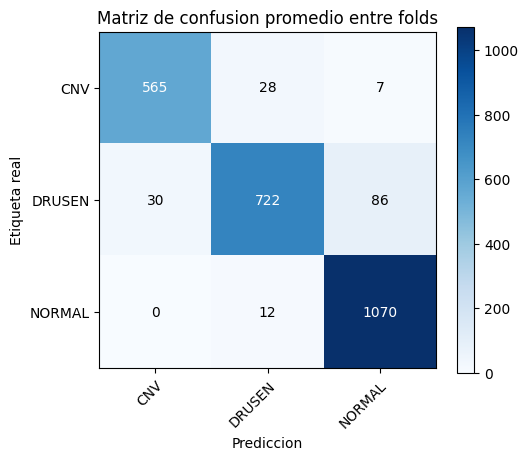

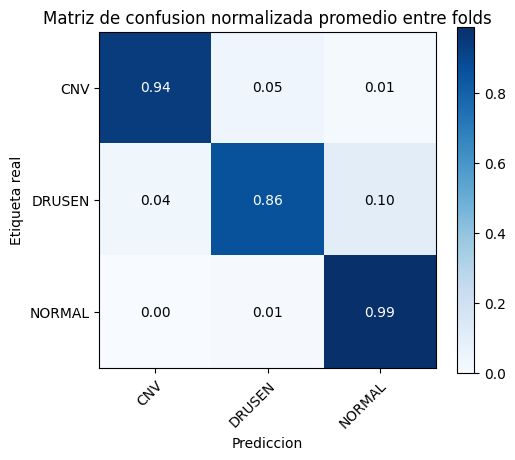

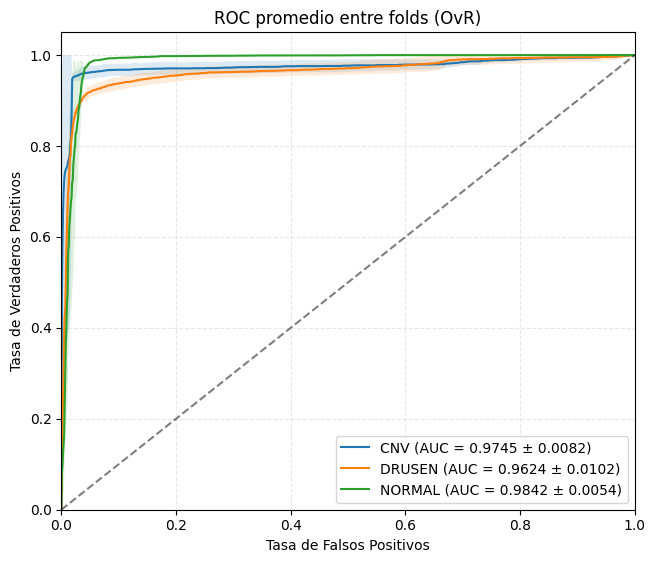


AUC promedio por clase:
CNV       : 0.9745 ± 0.0082
DRUSEN    : 0.9624 ± 0.0102
NORMAL    : 0.9842 ± 0.0054

Macro AUC: 0.9740 ± 0.0049
Micro AUC: 0.9766 ± 0.0052

Resultados exportados en: /content/drive/MyDrive/TesisIA/checkpoints_cswin_fpn_A100/eval_exports_CSWinFPN_5fold


In [20]:
# ============================================================
# CODEx update 2026-04-07: EVALUACION 5-FOLD completa
#   - Test externo en todos los folds
#   - Metricas por fold
#   - Promedio Â± std
#   - Metricas promedio por clase
#   - Matrices de confusion promedio
#   - ROC promedio entre folds
#   - Exportacion completa
#   - Tiempos de inferencia y entrenamiento
# ============================================================
import os
import json
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

from tqdm.auto import tqdm
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import label_binarize

# ------------------------------------------------------------
# 0) Configuracion
# ------------------------------------------------------------
IDX_TO_CLASS_EVAL = IDX_TO_CLASS if "IDX_TO_CLASS" in globals() else {0: "CNV", 1: "DRUSEN", 2: "NORMAL"}
CLASS_NAMES_EVAL = CLASS_NAMES if "CLASS_NAMES" in globals() else [IDX_TO_CLASS_EVAL[i] for i in range(NUM_CLASSES)]
DEVICE_EVAL = device if "device" in globals() else torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAVE_DIR_EVAL = TRAIN_SAVE_DIR if "TRAIN_SAVE_DIR" in globals() else str((DRIVE_ROOT / "checkpoints_cswin_fpn_A100") if "DRIVE_ROOT" in globals() else (Path("/content/drive/MyDrive/TesisIA") / "checkpoints_cswin_fpn_A100"))
FOLD_IDS_EVAL = sorted(best_ckpts.keys()) if "best_ckpts" in globals() and best_ckpts else list(range(1, (TRAIN_N_FOLDS if "TRAIN_N_FOLDS" in globals() else 5) + 1))

all_fold_best_paths = {
    int(fold_id): (best_ckpts[fold_id] if "best_ckpts" in globals() and fold_id in best_ckpts else os.path.join(SAVE_DIR_EVAL, f"best_cswin_fpn_fold{fold_id}.pt"))
    for fold_id in FOLD_IDS_EVAL
}
all_fold_best_paths = {fold_id: path for fold_id, path in all_fold_best_paths.items() if os.path.exists(path)}

OUT_EVAL = os.path.join(SAVE_DIR_EVAL, "eval_exports_CSWinFPN_5fold")
os.makedirs(OUT_EVAL, exist_ok=True)

ROC_GRID = np.linspace(0.0, 1.0, 1000)


# ------------------------------------------------------------
# 1) Funciones auxiliares
# ------------------------------------------------------------
def build_eval_model(num_classes):
    if "build_repo_fpn_classifier" in globals():
        return build_repo_fpn_classifier(num_classes=num_classes, target_device=DEVICE_EVAL, freeze_backbone=False)
    if "build_fpn_model" in globals():
        return build_fpn_model(num_classes=num_classes).to(DEVICE_EVAL)
    raise RuntimeError("No se encontro un constructor de modelo compatible para evaluacion.")


def load_checkpoint_for_eval(net, ckpt_path, map_location="cpu"):
    ck = torch.load(ckpt_path, map_location=map_location)
    state_dict = ck
    if isinstance(ck, dict):
        if "net" in ck:
            state_dict = ck["net"]
        elif "state_dict" in ck:
            state_dict = ck["state_dict"]
    net.load_state_dict(state_dict, strict=False)
    return ck


@torch.no_grad()
def predict_on_loader(net, loader, device, fold_id=None):
    net.eval()
    desc = f"Test Fold {fold_id}" if fold_id is not None else "Evaluando"

    y_true, y_pred, y_prob = [], [], []
    start_time = time.perf_counter()

    pbar = tqdm(loader, desc=desc, leave=True)
    for batch in pbar:
        if isinstance(batch, dict):
            xb = batch["image"].to(device, non_blocking=True)
            yb = batch["label"].to(device, non_blocking=True)
        else:
            xb, yb = batch
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

        output = net(xb)
        logits = output[0] if isinstance(output, (tuple, list)) else output
        probs = torch.softmax(logits, dim=1)
        preds = probs.argmax(dim=1)

        y_true.append(yb.detach().cpu().numpy())
        y_pred.append(preds.detach().cpu().numpy())
        y_prob.append(probs.detach().cpu().numpy())

        acc_batch = (preds == yb).float().mean().item()
        pbar.set_postfix(acc=f"{acc_batch:.3f}")

    elapsed = time.perf_counter() - start_time
    y_true = np.concatenate(y_true)
    y_pred = np.concatenate(y_pred)
    y_prob = np.concatenate(y_prob)

    timing = {
        "wall_time_sec": float(elapsed),
        "num_batches": int(len(loader)),
        "num_samples": int(len(y_true)),
        "sec_per_batch": float(elapsed / max(1, len(loader))),
        "ms_per_image": float((elapsed / max(1, len(y_true))) * 1000.0),
        "samples_per_sec": float(len(y_true) / max(elapsed, 1e-9)),
    }
    return y_true, y_pred, y_prob, timing


def plot_confusion_matrix(cm, class_names, title="Confusion Matrix", normalize=False, cmap="Blues"):
    fig, ax = plt.subplots(figsize=(5.4, 4.6))
    im = ax.imshow(cm, interpolation="nearest", cmap=cmap)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        ylabel="Etiqueta real",
        xlabel="Prediccion",
        title=title,
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    fmt = ".2f" if normalize else ".0f"
    thresh = cm.max() / 2.0 if cm.size > 0 else 0.5

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, format(cm[i, j], fmt),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black"
            )

    fig.tight_layout()
    plt.show()


def _safe_binary_roc(y_true_bin, y_score):
    unique_vals = np.unique(y_true_bin)
    if unique_vals.size < 2:
        return np.array([0.0, 1.0]), np.array([0.0, 1.0]), np.nan
    fpr, tpr, _ = roc_curve(y_true_bin, y_score)
    return fpr, tpr, auc(fpr, tpr)


def compute_multiclass_roc(y_true, y_prob, num_classes):
    y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))

    fpr = {}
    tpr = {}
    roc_auc = {}

    for i in range(num_classes):
        fpr[i], tpr[i], roc_auc[i] = _safe_binary_roc(y_true_bin[:, i], y_prob[:, i])

    micro_fpr, micro_tpr, micro_auc = _safe_binary_roc(y_true_bin.ravel(), y_prob.ravel())
    fpr["micro"], tpr["micro"], roc_auc["micro"] = micro_fpr, micro_tpr, micro_auc

    valid_class_ids = [i for i in range(num_classes) if not np.isnan(roc_auc[i])]
    if valid_class_ids:
        all_fpr = np.unique(np.concatenate([fpr[i] for i in valid_class_ids]))
        mean_tpr = np.zeros_like(all_fpr)
        for i in valid_class_ids:
            mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
        mean_tpr /= len(valid_class_ids)
        fpr["macro"] = all_fpr
        tpr["macro"] = mean_tpr
        roc_auc["macro"] = auc(all_fpr, mean_tpr)
    else:
        fpr["macro"] = np.array([0.0, 1.0])
        tpr["macro"] = np.array([0.0, 1.0])
        roc_auc["macro"] = np.nan

    return fpr, tpr, roc_auc


# ------------------------------------------------------------
# 2) Evaluar todos los folds en test externo
# ------------------------------------------------------------
all_test_results = {}

for fold_id in sorted(all_fold_best_paths.keys()):
    ckpt_path = all_fold_best_paths[fold_id]
    if not os.path.exists(ckpt_path):
        print(f"[Fold {fold_id}] Checkpoint no encontrado: {ckpt_path}")
        continue

    print("\n" + "=" * 90)
    print(f"Evaluando fold {fold_id} en test externo")
    print(f"Checkpoint: {ckpt_path}")
    print("=" * 90)

    net = build_eval_model(num_classes=NUM_CLASSES)
    ck = load_checkpoint_for_eval(net, ckpt_path, map_location="cpu")
    net = net.to(DEVICE_EVAL)

    y_true, y_pred, y_prob, test_timing = predict_on_loader(net, test_loader, DEVICE_EVAL, fold_id=fold_id)

    acc = accuracy_score(y_true, y_pred)

    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    report_dict = classification_report(
        y_true, y_pred,
        target_names=CLASS_NAMES_EVAL,
        digits=4,
        zero_division=0,
        output_dict=True
    )

    report_text = classification_report(
        y_true, y_pred,
        target_names=CLASS_NAMES_EVAL,
        digits=4,
        zero_division=0
    )

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    cm_norm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)), normalize="true")

    fpr, tpr, roc_auc = compute_multiclass_roc(y_true, y_prob, NUM_CLASSES)

    train_history = histories.get(fold_id, {}) if "histories" in globals() else {}
    train_times = np.array(train_history.get("train_time_total_sec", []), dtype=float)
    val_times = np.array(train_history.get("val_time_total_sec", []), dtype=float)

    all_test_results[fold_id] = {
        "y_true": y_true.tolist(),
        "y_pred": y_pred.tolist(),
        "y_prob": y_prob.tolist(),
        "acc": float(acc),
        "precision_macro": float(prec_macro),
        "recall_macro": float(rec_macro),
        "f1_macro": float(f1_macro),
        "precision_weighted": float(prec_weighted),
        "recall_weighted": float(rec_weighted),
        "f1_weighted": float(f1_weighted),
        "report_dict": report_dict,
        "report_text": report_text,
        "cm": cm.tolist(),
        "cm_norm": cm_norm.tolist(),
        "fpr": {str(k): np.asarray(v).tolist() for k, v in fpr.items()},
        "tpr": {str(k): np.asarray(v).tolist() for k, v in tpr.items()},
        "roc_auc": {str(k): (float(v) if not np.isnan(v) else None) for k, v in roc_auc.items()},
        "ckpt_path": ckpt_path,
        "test_timing": test_timing,
        "train_timing": {
            "train_time_total_sec": float(train_times.sum()) if train_times.size else None,
            "val_time_total_sec": float(val_times.sum()) if val_times.size else None,
            "fold_wall_time_sec": float(train_history.get("fold_wall_time_sec")) if "fold_wall_time_sec" in train_history else None,
            "mean_train_ms_per_image": float(np.mean(train_history.get("train_ms_per_image", []))) if train_history.get("train_ms_per_image") else None,
            "mean_val_ms_per_image": float(np.mean(train_history.get("val_ms_per_image", []))) if train_history.get("val_ms_per_image") else None,
        },
    }

    print(f"Accuracy           : {acc:.4f}")
    print(f"Precision macro    : {prec_macro:.4f}")
    print(f"Recall macro       : {rec_macro:.4f}")
    print(f"F1 macro           : {f1_macro:.4f}")
    print(f"Precision weighted : {prec_weighted:.4f}")
    print(f"Recall weighted    : {rec_weighted:.4f}")
    print(f"F1 weighted        : {f1_weighted:.4f}")
    print(f"Macro AUC          : {roc_auc['macro']:.4f}" if not np.isnan(roc_auc["macro"]) else "Macro AUC          : nan")
    print(f"Micro AUC          : {roc_auc['micro']:.4f}" if not np.isnan(roc_auc["micro"]) else "Micro AUC          : nan")
    print(
        f"Test time (sec)    : {test_timing['wall_time_sec']:.2f}\n"
        f"Test ms / image    : {test_timing['ms_per_image']:.2f}\n"
        f"Test FPS aprox.    : {test_timing['samples_per_sec']:.2f}"
    )

    del net, ck
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 3) Tabla resumen por fold
# ------------------------------------------------------------
summary_rows = []
for fold_id in sorted(all_test_results.keys()):
    res = all_test_results[fold_id]

    row = {
        "fold_id": fold_id,
        "acc": res["acc"],
        "precision_macro": res["precision_macro"],
        "recall_macro": res["recall_macro"],
        "f1_macro": res["f1_macro"],
        "precision_weighted": res["precision_weighted"],
        "recall_weighted": res["recall_weighted"],
        "f1_weighted": res["f1_weighted"],
        "auc_macro": res["roc_auc"]["macro"],
        "auc_micro": res["roc_auc"]["micro"],
        "test_time_sec": res["test_timing"]["wall_time_sec"],
        "test_ms_per_image": res["test_timing"]["ms_per_image"],
        "test_samples_per_sec": res["test_timing"]["samples_per_sec"],
        "train_time_total_sec": res["train_timing"]["train_time_total_sec"],
        "val_time_total_sec": res["train_timing"]["val_time_total_sec"],
        "fold_wall_time_sec": res["train_timing"]["fold_wall_time_sec"],
        "mean_train_ms_per_image": res["train_timing"]["mean_train_ms_per_image"],
        "mean_val_ms_per_image": res["train_timing"]["mean_val_ms_per_image"],
    }

    for i, cname in enumerate(CLASS_NAMES_EVAL):
        row[f"auc_{cname.lower()}"] = res["roc_auc"].get(str(i))

    rep = res["report_dict"]
    for cname in CLASS_NAMES_EVAL:
        row[f"{cname.lower()}_precision"] = rep[cname]["precision"]
        row[f"{cname.lower()}_recall"] = rep[cname]["recall"]
        row[f"{cname.lower()}_f1"] = rep[cname]["f1-score"]

    summary_rows.append(row)

df_test_summary = pd.DataFrame(summary_rows).sort_values("fold_id").reset_index(drop=True)

print("\n" + "=" * 90)
print("Resumen por fold")
print("=" * 90)
display(df_test_summary)


# ------------------------------------------------------------
# 4) Promedio ± std global
# ------------------------------------------------------------
numeric_cols = [c for c in df_test_summary.columns if c != "fold_id"]

summary_stats_rows = []
print("\n" + "=" * 90)
print("Promedio ± desviacion estandar")
print("=" * 90)

for col in numeric_cols:
    vals = pd.to_numeric(df_test_summary[col], errors="coerce").dropna().values.astype(float)
    mean = vals.mean() if len(vals) else np.nan
    std = vals.std(ddof=1) if len(vals) > 1 else 0.0
    summary_stats_rows.append({
        "metric": col,
        "mean": mean,
        "std": std,
        "mean_std_str": f"{mean:.4f} ± {std:.4f}" if not np.isnan(mean) else "nan ± nan",
    })
    print(f"{col:24s}: {mean:.4f} ± {std:.4f}" if not np.isnan(mean) else f"{col:24s}: nan ± nan")

df_summary_stats = pd.DataFrame(summary_stats_rows)
display(df_summary_stats)


# ------------------------------------------------------------
# 5) Tabla promedio por clase
# ------------------------------------------------------------
per_class_rows = []
for cname in CLASS_NAMES_EVAL:
    pvals = pd.to_numeric(df_test_summary[f"{cname.lower()}_precision"], errors="coerce").dropna().values.astype(float)
    rvals = pd.to_numeric(df_test_summary[f"{cname.lower()}_recall"], errors="coerce").dropna().values.astype(float)
    fvals = pd.to_numeric(df_test_summary[f"{cname.lower()}_f1"], errors="coerce").dropna().values.astype(float)
    aucvals = pd.to_numeric(df_test_summary[f"auc_{cname.lower()}"], errors="coerce").dropna().values.astype(float)

    per_class_rows.append({
        "class": cname,
        "precision_mean": pvals.mean() if len(pvals) else np.nan,
        "precision_std": pvals.std(ddof=1) if len(pvals) > 1 else 0.0,
        "recall_mean": rvals.mean() if len(rvals) else np.nan,
        "recall_std": rvals.std(ddof=1) if len(rvals) > 1 else 0.0,
        "f1_mean": fvals.mean() if len(fvals) else np.nan,
        "f1_std": fvals.std(ddof=1) if len(fvals) > 1 else 0.0,
        "auc_mean": aucvals.mean() if len(aucvals) else np.nan,
        "auc_std": aucvals.std(ddof=1) if len(aucvals) > 1 else 0.0,
    })

df_per_class_summary = pd.DataFrame(per_class_rows)

print("\n" + "=" * 90)
print("Metricas promedio por clase")
print("=" * 90)
display(df_per_class_summary)


# ------------------------------------------------------------
# 6) Matrices de confusion promedio entre folds
# ------------------------------------------------------------
cms = np.stack([np.array(all_test_results[f]["cm"], dtype=float) for f in sorted(all_test_results.keys())], axis=0)
cms_norm = np.stack([np.array(all_test_results[f]["cm_norm"], dtype=float) for f in sorted(all_test_results.keys())], axis=0)

cm_mean = cms.mean(axis=0)
cm_std = cms.std(axis=0, ddof=1) if cms.shape[0] > 1 else np.zeros_like(cm_mean)

cm_norm_mean = cms_norm.mean(axis=0)
cm_norm_std = cms_norm.std(axis=0, ddof=1) if cms_norm.shape[0] > 1 else np.zeros_like(cm_norm_mean)

print("\nMatriz de confusion promedio (conteos):")
print(cm_mean)

print("\nMatriz de confusion promedio normalizada:")
print(cm_norm_mean)

plot_confusion_matrix(
    cm_mean,
    CLASS_NAMES_EVAL,
    title="Matriz de confusion promedio entre folds",
    normalize=False,
)

plot_confusion_matrix(
    cm_norm_mean,
    CLASS_NAMES_EVAL,
    title="Matriz de confusion normalizada promedio entre folds",
    normalize=True,
)


# ------------------------------------------------------------
# 7) ROC promedio entre folds
# ------------------------------------------------------------
roc_curves_interp = {i: [] for i in range(NUM_CLASSES)}
roc_auc_by_class = {i: [] for i in range(NUM_CLASSES)}
roc_auc_macro_all = []
roc_auc_micro_all = []

for fold_id in sorted(all_test_results.keys()):
    res = all_test_results[fold_id]

    for i in range(NUM_CLASSES):
        fold_auc = res["roc_auc"].get(str(i))
        if fold_auc is None:
            continue
        fold_fpr = np.array(res["fpr"][str(i)], dtype=float)
        fold_tpr = np.array(res["tpr"][str(i)], dtype=float)
        interp_tpr = np.interp(ROC_GRID, fold_fpr, fold_tpr)
        interp_tpr[0] = 0.0
        roc_curves_interp[i].append(interp_tpr)
        roc_auc_by_class[i].append(float(fold_auc))

    if res["roc_auc"]["macro"] is not None:
        roc_auc_macro_all.append(float(res["roc_auc"]["macro"]))
    if res["roc_auc"]["micro"] is not None:
        roc_auc_micro_all.append(float(res["roc_auc"]["micro"]))

plt.figure(figsize=(7.4, 6.2))

for i, cname in enumerate(CLASS_NAMES_EVAL):
    if not roc_curves_interp[i]:
        continue
    tprs = np.vstack(roc_curves_interp[i])
    mean_tpr = tprs.mean(axis=0)
    std_tpr = tprs.std(axis=0, ddof=1) if tprs.shape[0] > 1 else np.zeros_like(mean_tpr)
    mean_tpr[-1] = 1.0

    auc_mean = np.mean(roc_auc_by_class[i]) if roc_auc_by_class[i] else np.nan
    auc_std = np.std(roc_auc_by_class[i], ddof=1) if len(roc_auc_by_class[i]) > 1 else 0.0

    plt.plot(
        ROC_GRID, mean_tpr,
        label=f"{cname} (AUC = {auc_mean:.4f} ± {auc_std:.4f})"
    )
    plt.fill_between(
        ROC_GRID,
        np.maximum(mean_tpr - std_tpr, 0),
        np.minimum(mean_tpr + std_tpr, 1),
        alpha=0.15,
    )

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("ROC promedio entre folds (OvR)")
plt.legend(loc="lower right")
plt.grid(True, ls="--", alpha=0.3)
plt.show()

print("\nAUC promedio por clase:")
for i, cname in enumerate(CLASS_NAMES_EVAL):
    vals = np.array(roc_auc_by_class[i], dtype=float)
    if len(vals):
        print(f"{cname:10s}: {vals.mean():.4f} ± {vals.std(ddof=1) if len(vals) > 1 else 0.0:.4f}")
    else:
        print(f"{cname:10s}: nan ± nan")

roc_auc_macro_all = np.array(roc_auc_macro_all, dtype=float)
roc_auc_micro_all = np.array(roc_auc_micro_all, dtype=float)

print(f"\nMacro AUC: {roc_auc_macro_all.mean():.4f} ± {roc_auc_macro_all.std(ddof=1) if len(roc_auc_macro_all) > 1 else 0.0:.4f}" if len(roc_auc_macro_all) else "\nMacro AUC: nan ± nan")
print(f"Micro AUC: {roc_auc_micro_all.mean():.4f} ± {roc_auc_micro_all.std(ddof=1) if len(roc_auc_micro_all) > 1 else 0.0:.4f}" if len(roc_auc_micro_all) else "Micro AUC: nan ± nan")


# ------------------------------------------------------------
# 9) Exportacion
# ------------------------------------------------------------
df_test_summary.to_csv(os.path.join(OUT_EVAL, "test_summary_by_fold.csv"), index=False)
df_summary_stats.to_csv(os.path.join(OUT_EVAL, "test_summary_mean_std.csv"), index=False)
df_per_class_summary.to_csv(os.path.join(OUT_EVAL, "test_per_class_mean_std.csv"), index=False)

with open(os.path.join(OUT_EVAL, "evaluation_summary.json"), "w", encoding="utf-8") as f:
    json.dump(
        {
            "all_fold_best_paths": {str(k): v for k, v in all_fold_best_paths.items()},
            "global_mean_std": {
                row["metric"]: {
                    "mean": (float(row["mean"]) if not pd.isna(row["mean"]) else None),
                    "std": (float(row["std"]) if not pd.isna(row["std"]) else None),
                    "mean_std_str": row["mean_std_str"],
                }
                for _, row in df_summary_stats.iterrows()
            },
            "per_class_mean_std": {
                row["class"]: {
                    "precision_mean": (float(row["precision_mean"]) if not pd.isna(row["precision_mean"]) else None),
                    "precision_std": (float(row["precision_std"]) if not pd.isna(row["precision_std"]) else None),
                    "recall_mean": (float(row["recall_mean"]) if not pd.isna(row["recall_mean"]) else None),
                    "recall_std": (float(row["recall_std"]) if not pd.isna(row["recall_std"]) else None),
                    "f1_mean": (float(row["f1_mean"]) if not pd.isna(row["f1_mean"]) else None),
                    "f1_std": (float(row["f1_std"]) if not pd.isna(row["f1_std"]) else None),
                    "auc_mean": (float(row["auc_mean"]) if not pd.isna(row["auc_mean"]) else None),
                    "auc_std": (float(row["auc_std"]) if not pd.isna(row["auc_std"]) else None),
                }
                for _, row in df_per_class_summary.iterrows()
            },
            "cm_mean": cm_mean.tolist(),
            "cm_std": cm_std.tolist(),
            "cm_norm_mean": cm_norm_mean.tolist(),
            "cm_norm_std": cm_norm_std.tolist(),
            "all_test_results": all_test_results,
        },
        f,
        indent=2,
        ensure_ascii=False,
    )

print(f"\nResultados exportados en: {OUT_EVAL}")


In [ ]:
# ============================================================
#  Restaurar módulo CSWin si 'm' fue sobrescrito
# ============================================================
import importlib
import sys

if CSWIN_DIR not in sys.path:
    sys.path.insert(0, CSWIN_DIR)

m = importlib.import_module("models.cswin")
print("âœ… MÃ³dulo restaurado:", m)
print("CSWinTransformer:", hasattr(m, "CSWinTransformer"))

Analisis cualitativo: Grad-CAM ilustrativo usando fold 5
Esta visualizacion corresponde a un solo modelo y no al promedio entre folds.


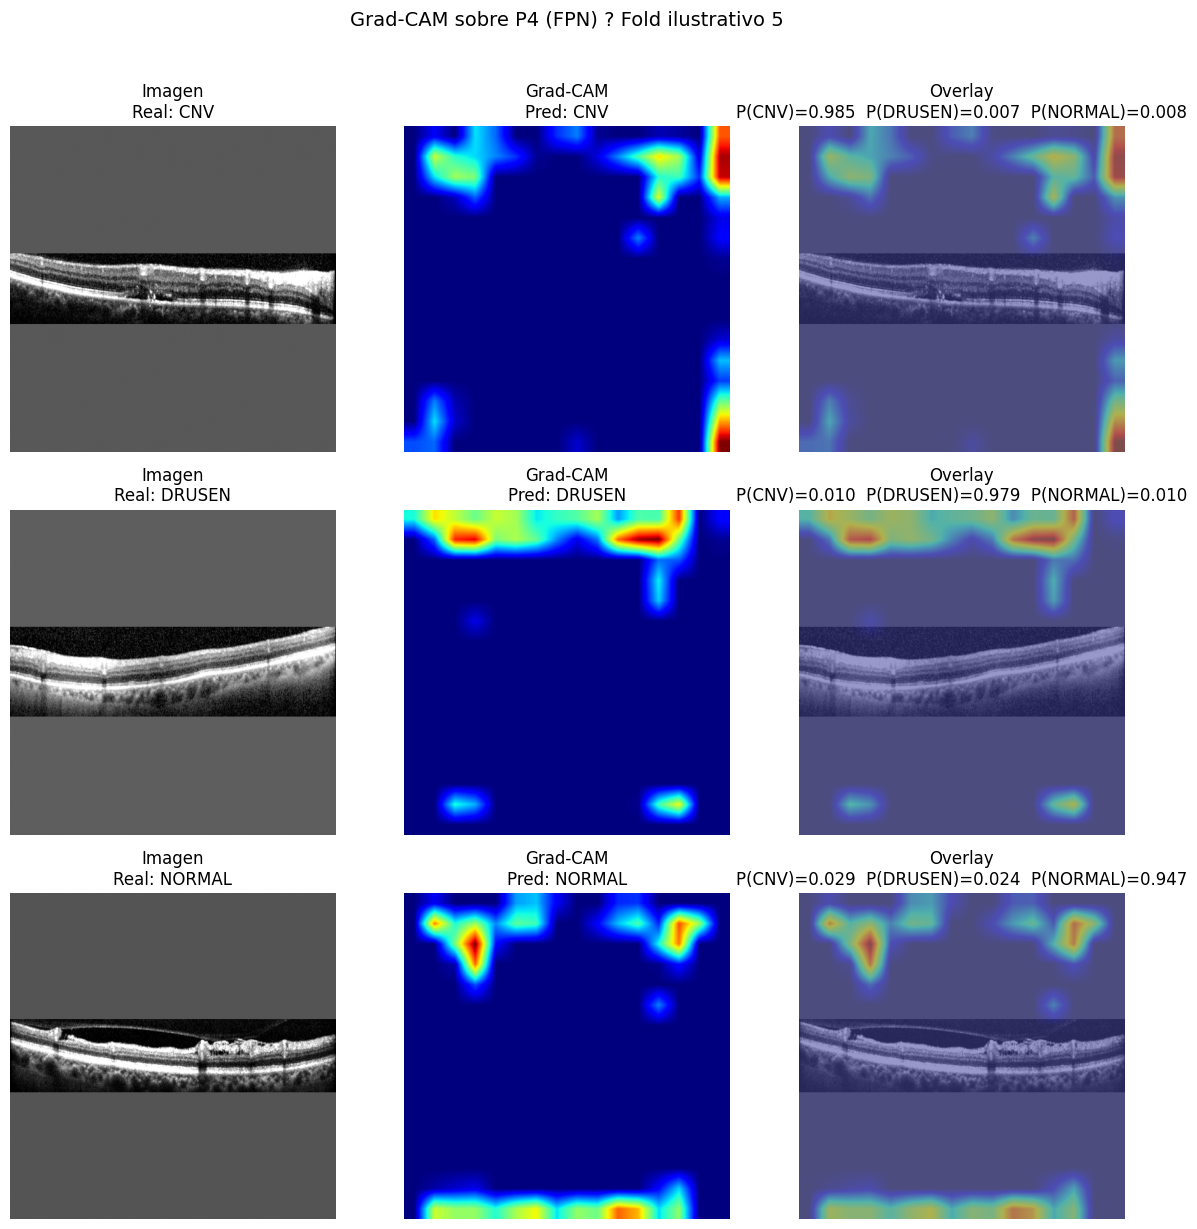

In [21]:
# ============================================================
#    Grad-CAM cualitativo sobre P4 (FPN)
#   - Analisis cualitativo ilustrativo
#   - Usa un fold individual solo para visualizacion
#   - No representa el promedio 5-fold
# ============================================================
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

CLASS_NAMES_CAM = CLASS_NAMES if "CLASS_NAMES" in globals() else [IDX_TO_CLASS[i] for i in range(NUM_CLASSES)]
DEVICE_CAM = device if "device" in globals() else torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUALITATIVE_FOLD_ID = globals().get("QUALITATIVE_FOLD_ID", (5 if 5 in all_fold_best_paths else sorted(all_fold_best_paths.keys())[0]))
QUALITATIVE_CKPT_PATH = all_fold_best_paths[QUALITATIVE_FOLD_ID]

print(f"Analisis cualitativo: Grad-CAM ilustrativo usando fold {QUALITATIVE_FOLD_ID}")
print("Esta visualizacion corresponde a un solo modelo y no al promedio entre folds.")


def build_cam_model(num_classes):
    if "build_eval_model" in globals():
        return build_eval_model(num_classes)
    if "build_repo_fpn_classifier" in globals():
        return build_repo_fpn_classifier(num_classes=num_classes, target_device=DEVICE_CAM, freeze_backbone=False)
    return build_fpn_model(num_classes=num_classes).to(DEVICE_CAM)


def load_cam_checkpoint(net, ckpt_path):
    if "load_checkpoint_for_eval" in globals():
        return load_checkpoint_for_eval(net, ckpt_path, map_location="cpu")
    ck = torch.load(ckpt_path, map_location="cpu")
    state_dict = ck["net"] if isinstance(ck, dict) and "net" in ck else ck
    net.load_state_dict(state_dict, strict=False)
    return ck


def unpack_batch_for_vis(batch):
    if isinstance(batch, dict):
        return batch["image"], batch["label"]
    return batch


net_cam = build_cam_model(num_classes=NUM_CLASSES)
_ = load_cam_checkpoint(net_cam, QUALITATIVE_CKPT_PATH)
net_cam = net_cam.to(DEVICE_CAM)
net_cam.eval()

IDX_TO_CLASS_CAM = IDX_TO_CLASS if "IDX_TO_CLASS" in globals() else {
    0: "CNV",
    1: "DRUSEN",
    2: "NORMAL",
}


def to_vis(img_tensor, window=(-2, 2)):
    if torch.is_tensor(img_tensor):
        img = img_tensor.detach().cpu().float().numpy()
    else:
        img = img_tensor

    if img.ndim == 3:
        img = img[0]

    if window is not None:
        lo, hi = window
        img = np.clip(img, lo, hi)
        img = (img - lo) / (hi - lo + 1e-6)
    else:
        mn, mx = img.min(), img.max()
        img = (img - mn) / (mx - mn + 1e-6)

    return img


def overlay_heatmap_on_grayscale(img_vis, cam_norm, alpha=0.40):
    cmap = plt.get_cmap("jet")
    heat = cmap(cam_norm)[..., :3]
    base = np.stack([img_vis, img_vis, img_vis], axis=-1)
    overlay = (1 - alpha) * base + alpha * heat
    overlay = np.clip(overlay, 0, 1)
    return heat, overlay


def collect_one_correct_example_per_class(net, loader, num_classes=3):
    found = {}
    net.eval()
    with torch.no_grad():
        for batch in loader:
            xb, yb = unpack_batch_for_vis(batch)
            logits = net(xb.to(DEVICE_CAM))
            preds = logits.argmax(dim=1).detach().cpu()
            for i in range(xb.size(0)):
                cls = int(yb[i].item())
                pred = int(preds[i].item())
                if cls == pred and cls not in found:
                    found[cls] = (xb[i:i+1].clone(), cls)
                if len(found) == num_classes:
                    return found
    return found


def get_gradcam_target_layer(net):
    if hasattr(net, "fpn") and hasattr(net.fpn, "s4"):
        return net.fpn.s4
    if hasattr(net, "fpn") and hasattr(net.fpn, "smooth") and len(net.fpn.smooth) >= 4:
        return net.fpn.smooth[3]
    raise RuntimeError("No se encontro una capa equivalente a P4 / s4 para Grad-CAM.")


def gradcam_for_sample(net, x, target_layer, class_idx=None):
    activations = {}
    gradients = {}

    def fwd_hook(module, inp, out):
        activations["value"] = out

    def bwd_hook(module, grad_input, grad_output):
        gradients["value"] = grad_output[0]

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    net.zero_grad(set_to_none=True)

    x = x.to(DEVICE_CAM)
    output = net(x)
    logits = output[0] if isinstance(output, (tuple, list)) else output
    probs = torch.softmax(logits, dim=1)[0].detach().cpu().numpy()
    pred_idx = int(logits.argmax(dim=1).item())

    if class_idx is None:
        class_idx = pred_idx

    score = logits[:, class_idx].sum()
    score.backward()

    acts = activations["value"]
    grads = gradients["value"]
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = (weights * acts).sum(dim=1, keepdim=True)
    cam = F.relu(cam)

    cam_up = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam_up = cam_up[0, 0]

    cam_up = cam_up - cam_up.min()
    cam_up = cam_up / (cam_up.max() + 1e-8)
    cam_up_norm = cam_up.detach().cpu().numpy()

    h1.remove()
    h2.remove()

    return cam_up_norm, pred_idx, probs


examples = collect_one_correct_example_per_class(net_cam, test_loader, num_classes=NUM_CLASSES)
missing_classes = [c for c in range(NUM_CLASSES) if c not in examples]
if missing_classes:
    raise RuntimeError(f"No se encontraron ejemplos correctamente clasificados para clases: {missing_classes}")

target_layer = get_gradcam_target_layer(net_cam)

fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(12, 4 * NUM_CLASSES))
if NUM_CLASSES == 1:
    axes = np.expand_dims(axes, axis=0)

for row, cls in enumerate(range(NUM_CLASSES)):
    x, y_true = examples[cls]

    cam_norm, pred_idx, probs = gradcam_for_sample(
        net=net_cam,
        x=x,
        target_layer=target_layer,
        class_idx=None,
    )

    img_vis = to_vis(x[0, 0], window=(-2, 2))
    heat, overlay = overlay_heatmap_on_grayscale(img_vis, cam_norm, alpha=0.40)

    axes[row, 0].imshow(img_vis, cmap="gray")
    axes[row, 0].set_title(f"Imagen\nReal: {IDX_TO_CLASS_CAM[y_true]}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(cam_norm, cmap="jet")
    axes[row, 1].set_title(f"Grad-CAM\nPred: {IDX_TO_CLASS_CAM[pred_idx]}")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(
        "Overlay\n" +
        f"P(CNV)={probs[0]:.3f}  P(DRUSEN)={probs[1]:.3f}  P(NORMAL)={probs[2]:.3f}"
    )
    axes[row, 2].axis("off")

plt.suptitle(
    f"Grad-CAM sobre P4 (FPN) ? Fold ilustrativo {QUALITATIVE_FOLD_ID}",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()


Analisis cualitativo: mapa complementario C4 usando fold 5
Esta visualizacion corresponde a un solo modelo y no al promedio entre folds.


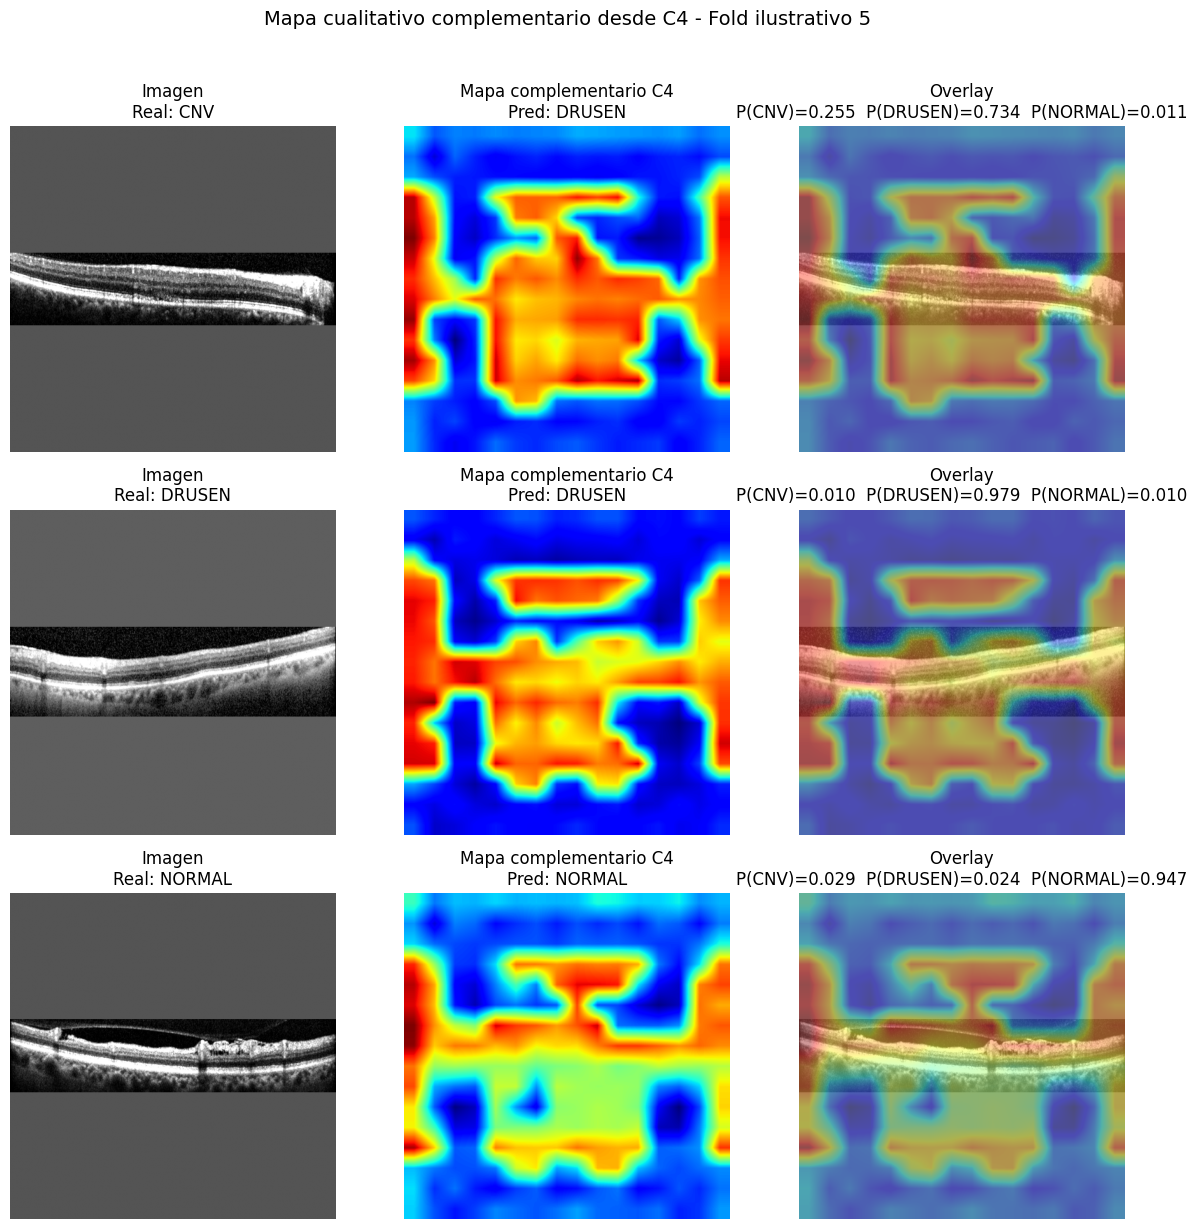

Shape de C4 usado para el mapa: (1, 512, 16, 16)


In [22]:
# ============================================================
#    Mapa cualitativo complementario desde C4
#   - Analisis cualitativo ilustrativo
#   - Usa un fold individual solo para visualizacion
#   - No representa el promedio 5-fold
# ============================================================
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

CLASS_NAMES_ATT = CLASS_NAMES if "CLASS_NAMES" in globals() else [IDX_TO_CLASS[i] for i in range(NUM_CLASSES)]
DEVICE_ATT = device if "device" in globals() else torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUALITATIVE_FOLD_ID = globals().get("QUALITATIVE_FOLD_ID", sorted(all_fold_best_paths.keys())[0])
QUALITATIVE_CKPT_PATH = all_fold_best_paths[QUALITATIVE_FOLD_ID]

print(f"Analisis cualitativo: mapa complementario C4 usando fold {QUALITATIVE_FOLD_ID}")
print("Esta visualizacion corresponde a un solo modelo y no al promedio entre folds.")


def build_att_model(num_classes):
    if "build_eval_model" in globals():
        return build_eval_model(num_classes)
    if "build_repo_fpn_classifier" in globals():
        return build_repo_fpn_classifier(num_classes=num_classes, target_device=DEVICE_ATT, freeze_backbone=False)
    return build_fpn_model(num_classes=num_classes).to(DEVICE_ATT)


def load_att_checkpoint(net, ckpt_path):
    if "load_checkpoint_for_eval" in globals():
        return load_checkpoint_for_eval(net, ckpt_path, map_location="cpu")
    ck = torch.load(ckpt_path, map_location="cpu")
    state_dict = ck["net"] if isinstance(ck, dict) and "net" in ck else ck
    net.load_state_dict(state_dict, strict=False)
    return ck


def unpack_batch_for_vis(batch):
    if isinstance(batch, dict):
        return batch["image"], batch["label"]
    return batch


net_att = build_att_model(num_classes=NUM_CLASSES)
_ = load_att_checkpoint(net_att, QUALITATIVE_CKPT_PATH)
net_att = net_att.to(DEVICE_ATT)
net_att.eval()


def to_vis(img_tensor, window=(-2, 2)):
    if torch.is_tensor(img_tensor):
        img = img_tensor.detach().cpu().float().numpy()
    else:
        img = img_tensor
    if img.ndim == 3:
        img = img[0]
    if window is not None:
        lo, hi = window
        img = np.clip(img, lo, hi)
        img = (img - lo) / (hi - lo + 1e-6)
    else:
        mn, mx = img.min(), img.max()
        img = (img - mn) / (mx - mn + 1e-6)
    return img


def overlay_heatmap_on_grayscale(img_vis, map_norm, alpha=0.40):
    cmap = plt.get_cmap("jet")
    heat = cmap(map_norm)[..., :3]
    base = np.stack([img_vis, img_vis, img_vis], axis=-1)
    overlay = (1 - alpha) * base + alpha * heat
    return heat, np.clip(overlay, 0, 1)


def collect_one_example_per_class(loader, num_classes=3):
    found = {}
    for batch in loader:
        xb, yb = unpack_batch_for_vis(batch)
        for i in range(xb.size(0)):
            cls = int(yb[i].item())
            if cls not in found:
                found[cls] = (xb[i:i+1].clone(), cls)
            if len(found) == num_classes:
                return found
    return found


def _qual_tokens_to_bchw(x_tokens):
    B, N, C = x_tokens.shape
    H = W = int(np.sqrt(N))
    if H * W != N:
        raise ValueError(f"Tokens no cuadrados: N={N}")
    return x_tokens.view(B, H, W, C).permute(0, 3, 1, 2).contiguous()


def _qual_run_stage(stage_module, x):
    if isinstance(stage_module, torch.nn.ModuleList):
        for block in stage_module:
            x = block(x)
        return x
    return stage_module(x)


def forward_with_backbone_features(net, x):
    if hasattr(net, "backbone") and hasattr(net, "fpn") and hasattr(net, "head") and hasattr(net.backbone, "stage1_conv_embed"):
        m = net.backbone
        x = m.stage1_conv_embed(x)
        feats = []

        x = _qual_run_stage(m.stage1, x)
        feats.append(_qual_tokens_to_bchw(x))
        if hasattr(m, "merge1") and m.merge1 is not None:
            x = m.merge1(x)

        x = _qual_run_stage(m.stage2, x)
        feats.append(_qual_tokens_to_bchw(x))
        if hasattr(m, "merge2") and m.merge2 is not None:
            x = m.merge2(x)

        x = _qual_run_stage(m.stage3, x)
        feats.append(_qual_tokens_to_bchw(x))
        if hasattr(m, "merge3") and m.merge3 is not None:
            x = m.merge3(x)

        x = _qual_run_stage(m.stage4, x)
        feats.append(_qual_tokens_to_bchw(x))

        c4 = feats[-1]
        pyr = net.fpn(feats)
        logits = net.head(pyr)
        return logits, c4

    output = net(x)
    if isinstance(output, (tuple, list)) and len(output) >= 2:
        logits = output[0]
        feats = output[1]
        if isinstance(feats, dict) and "C4" in feats:
            return logits, feats["C4"]
        if isinstance(feats, (list, tuple)) and len(feats) >= 4:
            return logits, feats[-1]
    raise RuntimeError("No fue posible extraer un mapa C4 compatible para el analisis cualitativo.")


def c4_attention_proxy(net, x):
    x = x.to(DEVICE_ATT)
    with torch.no_grad():
        logits, c4 = forward_with_backbone_features(net, x)
        probs = torch.softmax(logits, dim=1)[0].detach().cpu().numpy()
        pred_idx = int(logits.argmax(dim=1).item())
        att = c4.abs().mean(dim=1, keepdim=True)
        att = att - att.amin(dim=(2, 3), keepdim=True)
        att = att / (att.amax(dim=(2, 3), keepdim=True) + 1e-8)
        att_up = F.interpolate(att, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
        att_up = att_up - att_up.min()
        att_up = att_up / (att_up.max() + 1e-8)
    return att_up, pred_idx, probs, tuple(c4.shape)


examples = collect_one_example_per_class(test_loader, num_classes=NUM_CLASSES)
missing_classes = [c for c in range(NUM_CLASSES) if c not in examples]
if missing_classes:
    raise RuntimeError(f"No se encontraron ejemplos para clases: {missing_classes}")

fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(12, 4 * NUM_CLASSES))
if NUM_CLASSES == 1:
    axes = np.expand_dims(axes, axis=0)

last_c4_shape = None
for row, cls in enumerate(range(NUM_CLASSES)):
    x, y_true = examples[cls]
    att_norm, pred_idx, probs, c4_shape = c4_attention_proxy(net_att, x)
    last_c4_shape = c4_shape
    img_vis = to_vis(x[0, 0], window=(-2, 2))
    _, overlay = overlay_heatmap_on_grayscale(img_vis, att_norm, alpha=0.40)
    probs_text = "  ".join([f"P({name})={prob:.3f}" for name, prob in zip(CLASS_NAMES_ATT, probs)])

    axes[row, 0].imshow(img_vis, cmap="gray")
    axes[row, 0].set_title(f"Imagen\nReal: {CLASS_NAMES_ATT[y_true]}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(att_norm, cmap="jet")
    axes[row, 1].set_title(f"Mapa complementario C4\nPred: {CLASS_NAMES_ATT[pred_idx]}")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("Overlay\n" + probs_text)
    axes[row, 2].axis("off")

plt.suptitle(
    f"Mapa cualitativo complementario desde C4 - Fold ilustrativo {QUALITATIVE_FOLD_ID}",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

print("Shape de C4 usado para el mapa:", last_c4_shape)
